# Taller 2 · Predicción de abandono de clientes

MINE-4101 Ciencia de Datos Aplicada · Universidad de los Andes · 2026-20

Sergio Perez 202314506 · Samuel Charry 202313509

Modelo que predice qué clientes de un banco van a abandonar, para enfocar la campaña de retención y calcular cuánto valor le deja al banco.

dependicias: `pip install lime shap`.

<a id='indice'></a>
# Índice

1. [Entendimiento y preparación de los datos](#s1)
   - 1.1 [Carga del dataset](#s1-1)
   - 1.2 [Dimensiones del dataset](#s1-2)
   - 1.3 [Tipos de variables](#s1-3)
   - 1.4 [Gráficos de distribución](#s1-4)
     - 1.4.1 [Variables continuas](#s1-4-1)
     - 1.4.2 [Variables categóricas y binarias](#s1-4-2)
     - 1.4.3 [Variable objetivo churn y desbalance](#s1-4-3)
   - 1.5 [Indicadores importantes: calidad de datos](#s1-5)
   - 1.6 [Preparación de los datos](#s1-6)
     - 1.6.1 [Duplicados](#s1-6-1)
     - 1.6.2 [Valores inválidos](#s1-6-2)
     - 1.6.3 [Outliers](#s1-6-3)
     - 1.6.4 [Valores nulos](#s1-6-4)
   - 1.7 [Selección de variables y codificación](#s1-7)
2. [Entrenamiento del modelo de Machine Learning](#s2)
   - 2.1 [División de los datos](#s2-1)
   - 2.2 [Modelo A: Regresión logística](#s2-2)
   - 2.3 [Modelo B: Random Forest](#s2-3)
3. [Análisis cuantitativo de resultados del modelo](#s3)
   - 3.1 [Métricas de evaluación](#s3-1)
   - 3.2 [Curvas precisión-recall y ROC](#s3-2)
   - 3.3 [Significado de las métricas para la empresa](#s3-3)
   - 3.4 [Justificación del modelo](#s3-4)
     - 3.4.1 [Elección en validación](#s3-4-1)
     - 3.4.2 [Evaluación en prueba](#s3-4-2)
     - 3.4.3 [Intervalos de confianza por bootstrapping](#s3-4-3)
     - 3.4.4 [Diferencia pareada de F1](#s3-4-4)
     - 3.4.5 [Prueba de McNemar](#s3-4-5)
   - 3.5 [Qué impactó las métricas y qué mejorar](#s3-5)
4. [Análisis cualitativo de resultados del modelo](#s4)
   - 4.1 [Comportamiento global](#s4-1)
   - 4.2 [Predicciones individuales](#s4-2)
   - 4.3 [Cómo funciona el modelo](#s4-3)
5. [Generación de valor](#s5)
   - 5.1 [Supuestos y fuentes](#s5-1)
   - 5.2 [Ganancia esperada por estimación](#s5-2)
   - 5.3 [Punto de equilibrio](#s5-3)
   - 5.4 [Estimación paramétrica](#s5-4)
   - 5.5 [Limitaciones](#s5-5)
6. [Insights e informe ejecutivo](#s6)
   - 6.1 [Hallazgos principales](#s6-1)
   - 6.2 [Resultados del modelo](#s6-2)
   - 6.3 [Recomendación final para el negocio](#s6-3)
7. [Declaración de uso de IA generativa](#s7)
   - 7.1 [Modelos y porcentaje de ayuda](#s7-1)
   - 7.2 [Prompts empleados](#s7-2)

<a id='s1'></a>
# 1. Entendimiento y Preparación de los Datos

> Esta sección responde:
> - ¿Cómo son los datos y qué problemas de calidad tienen?
> - ¿Cómo se limpiaron y qué variables se usan en el modelo?

<a id='s1-1'></a>
## 1.1 Carga del dataset

> Esta sección responde:
> - ¿Qué datos se usan?

In [1]:
import pandas as pd

df = pd.read_csv("churn.csv")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

> **¿Qué datos se usan?**
>
> churn.csv, la versión del curso que trae problemas de calidad a propósito. Cada fila es un cliente del banco y churn indica si abandonó.

<a id='s1-2'></a>
## 1.2 Dimensiones del dataset

> Esta sección responde:
> - ¿Qué tamaño tiene el dataset?

In [3]:
df.shape                        # Dimensión (número de filas, número de columnas)
df.dtypes                       # tipo de dato de cada columna
df.info()                       # tipos, valores no nulos y memoria en una sola vista
df.describe()                   # estadísticas de las columnas numéricas
#df.describe(include="object")   # conteo, valores únicos y moda de las columnas de texto


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  object 
 2   gender            10045 non-null  object 
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 863.4+ KB


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,9795.000000,9745.000000,10045.000000,9845.000000,10045.000000,10045.000000,10045.000000,9695.000000,10045.000000
mean,650.690148,38.937609,5.018915,76317.500287,1.530114,0.704530,0.514684,100069.014751,0.203584
std,97.087963,10.734222,2.901585,62422.434819,0.581829,0.456277,0.499809,57510.689111,0.402683
min,95.000000,-1.000000,-2.000000,0.000000,1.000000,0.000000,0.000000,-5000.000000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,51013.655000,0.000000
50%,652.000000,37.000000,5.000000,97042.600000,1.000000,1.000000,1.000000,100130.950000,0.000000
75%,718.000000,44.000000,8.000000,127559.970000,2.000000,1.000000,1.000000,149382.875000,0.000000
max,1200.000000,210.000000,25.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


> **¿Qué tamaño tiene el dataset?**
>
> 10.045 registros y 11 columnas antes de limpiar.

<a id='s1-3'></a>
## 1.3 Tipos de variables

> Esta sección responde:
> - ¿Qué tipos de variables hay?

| Variable | Descripción | Tipo (pandas) | Clasificación |
|---|---|---|---|
| credit_score | Puntaje crediticio (300 a 850) | float64 | Continua |
| age | Edad en años (18 a 100) | float64 | Continua |
| balance | Saldo de la cuenta (≥ 0) | float64 | Continua |
| estimated_salary | Salario estimado (≥ 0) | float64 | Continua |
| tenure | Años como cliente (0 a 10) | int64 | Discreta (numérica) |
| products_number | Número de productos (1 a 4) | int64 | Discreta / categórica ordinal |
| country | País de residencia | object | Categórica |
| gender | Género | object | Categórica |
| credit_card | Tiene tarjeta de crédito | int64 | Binaria |
| active_member | Es miembro activo | int64 | Binaria |
| churn | Abandonó el banco (variable objetivo) | int64 | Binaria |

In [4]:
for i in df.columns:
  print(f'{i}: {len(df[i].unique())}')


credit_score: 462
country: 9
gender: 4
age: 77
tenure: 14
balance: 6241
products_number: 4
credit_card: 2
active_member: 2
estimated_salary: 9650
churn: 2


In [5]:
continuas   = ["credit_score", "age", "balance", "estimated_salary"]
discretas   = ["tenure", "products_number"]
categoricas = ["country", "gender"]
binarias    = ["credit_card", "active_member", "churn"]

resumen = pd.DataFrame({
    "tipo": df.dtypes,
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "valores únicos": df.nunique(),
})
resumen

,tipo,nulos,% nulos,valores únicos
credit_score,float64,250,2.49,461
country,object,0,0.00,9
gender,object,0,0.00,4
age,float64,300,2.99,76
tenure,int64,0,0.00,14
balance,float64,200,1.99,6240
products_number,int64,0,0.00,4
credit_card,int64,0,0.00,2
active_member,int64,0,0.00,2
estimated_salary,float64,350,3.48,9649


> **¿Qué tipos de variables hay?**
>
> 4 continuas, 2 discretas, 2 categóricas y 3 binarias. churn es la variable objetivo. credit_score y age salen como float por los nulos, pero sus valores son enteros.

<a id='s1-4'></a>
## 1.4 Gráficos de distribución

> Esta sección responde:
> - ¿Cómo se distribuyen las variables?

<a id='s1-4-1'></a>
### 1.4.1 Variables continuas

> Esta sección responde:
> - ¿Cómo se distribuyen las variables continuas?
> - ¿Hay valores imposibles?

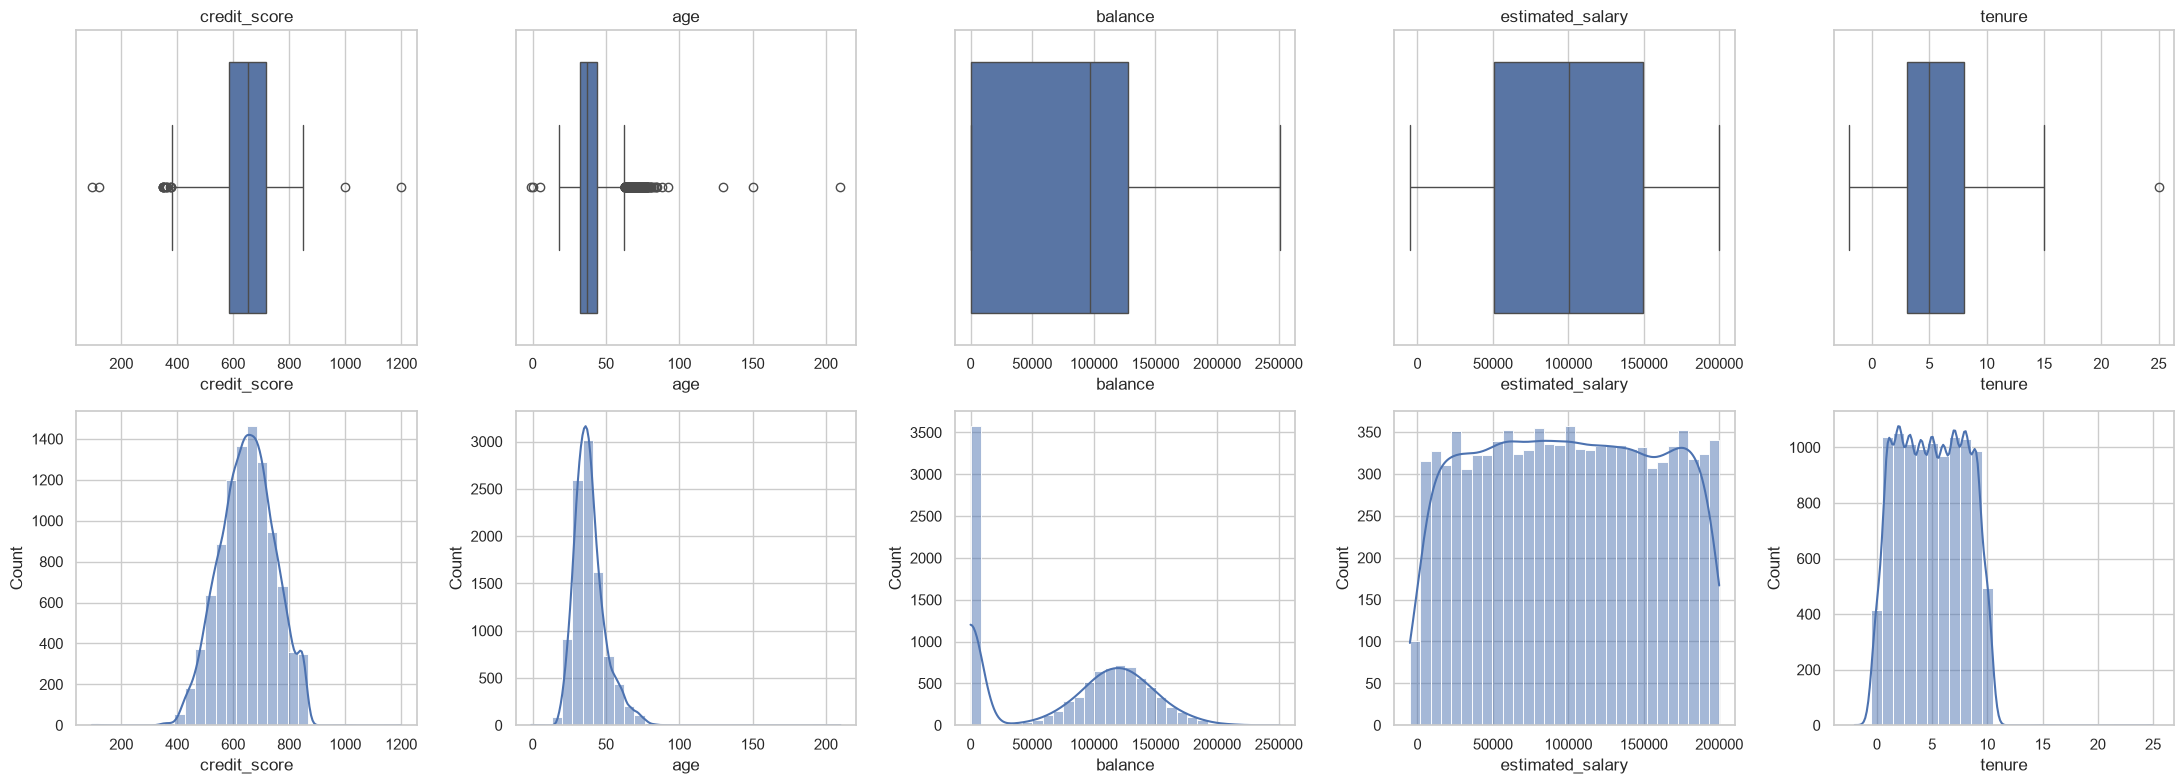

In [6]:
# Datos sin limpiar: también aparecen los valores inválidos
num_vars = continuas + ["tenure"]

fig, axes = plt.subplots(2, len(num_vars), figsize=(22, 8))
for i, col in enumerate(num_vars):
    sns.boxplot(x=df[col], ax=axes[0, i])
    axes[0, i].set_title(col)
    sns.histplot(df[col], bins=30, kde=True, discrete=(col == "tenure"), ax=axes[1, i])   # tenure: una barra por año
plt.tight_layout()
plt.show()

> **¿Cómo se distribuyen las variables continuas?**
>
> - credit_score: casi simétrica, centrada en ~650.
> - age: sesgada a la derecha. Hay muchos clientes entre 62 y 92 años; son clientes reales, no errores.
> - balance: más de un tercio tiene saldo 0 y el resto forma una campana alrededor de 120.000.
> - estimated_salary: casi uniforme entre 0 y 200.000.
> - tenure: casi uniforme entre 1 y 9 años.
>
> **¿Hay valores imposibles?**
>
> Sí: credit_score entre 95 y 1200, age entre -1 y 210, estimated_salary con un mínimo de -5.000 y tenure entre -2 y 25. Algunos quedan dentro de los bigotes, por eso también se revisan contra el diccionario en 1.5.

<a id='s1-4-2'></a>
### 1.4.2 Variables categóricas y binarias

> Esta sección responde:
> - ¿Cómo se reparten las variables categóricas y binarias?

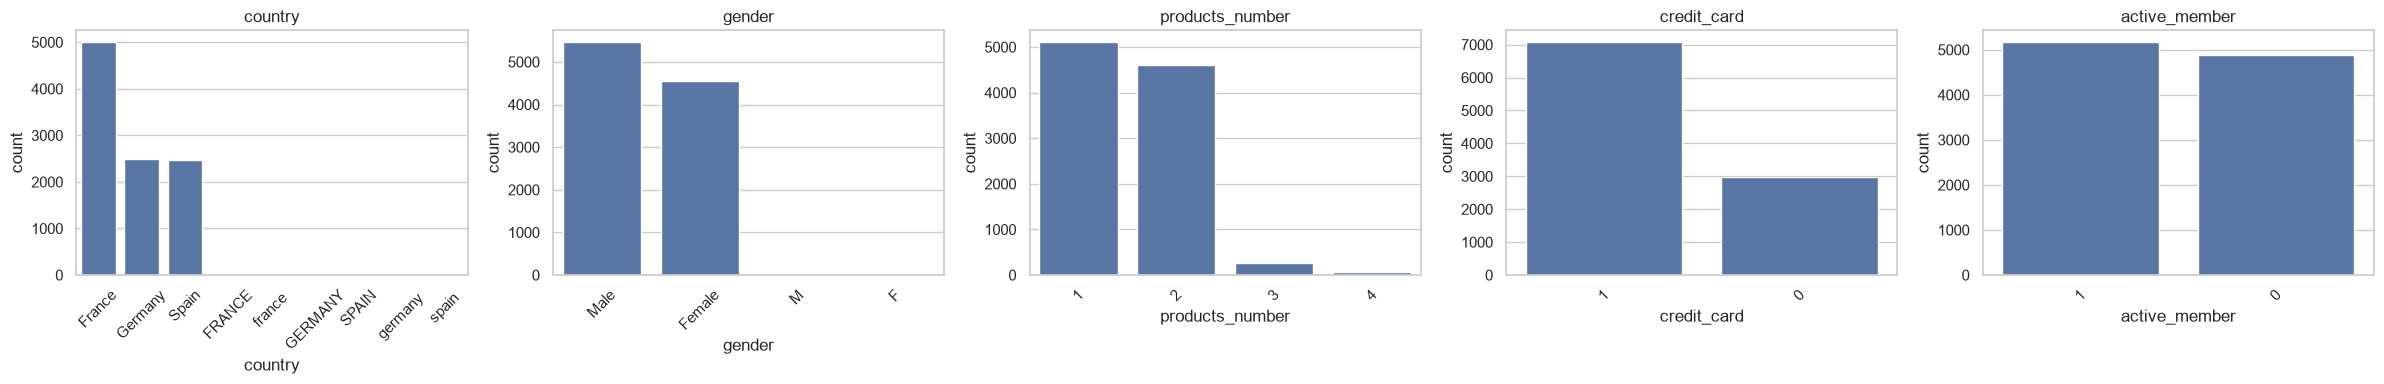

In [7]:
# Valores tal como vienen en el archivo, sin unificar la escritura
cat_vars = categoricas + ["products_number", "credit_card", "active_member"]

fig, axes = plt.subplots(1, len(cat_vars), figsize=(24, 4))
for ax, col in zip(axes, cat_vars):
    sns.countplot(x=col, data=df, order=df[col].value_counts().index, ax=ax)   # de la más a la menos frecuente
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# Proporciones (%) unificando la escritura solo para explorar; la corrección real se hace en la etapa de calidad
pais = df["country"].str.strip().str.title()
genero = df["gender"].str.strip().replace({"M": "Male", "F": "Female"})

for nombre, serie in [("country", pais), ("gender", genero), ("products_number", df["products_number"]),
                      ("credit_card", df["credit_card"]), ("active_member", df["active_member"])]:
    print(nombre, (serie.value_counts(normalize=True) * 100).round(1).to_dict())

country {'France': 50.2, 'Germany': 25.1, 'Spain': 24.7}
gender {'Male': 54.6, 'Female': 45.4}
products_number {1: 50.9, 2: 45.9, 3: 2.6, 4: 0.6}
credit_card {1: 70.5, 0: 29.5}
active_member {1: 51.5, 0: 48.5}


> **¿Cómo se reparten las variables categóricas y binarias?**
>
> - country: 50,2 % Francia, 25,1 % Alemania y 24,7 % España. Aparecen 9 escrituras distintas (FRANCE, france, etc.).
> - gender: 54,6 % hombres y 45,4 % mujeres, con M y F mezclados con Male y Female.
> - products_number: casi el 97 % tiene 1 o 2 productos.
> - credit_card: 70,5 % tiene tarjeta.
> - active_member: 51,5 % activos y 48,5 % inactivos.

<a id='s1-4-3'></a>
### 1.4.3 Variable objetivo churn y desbalance

> Esta sección responde:
> - ¿Qué proporción de clientes abandona?
> - ¿Qué implica el desbalance?

,registros,%
churn,,
0,8000,79.64
1,2045,20.36


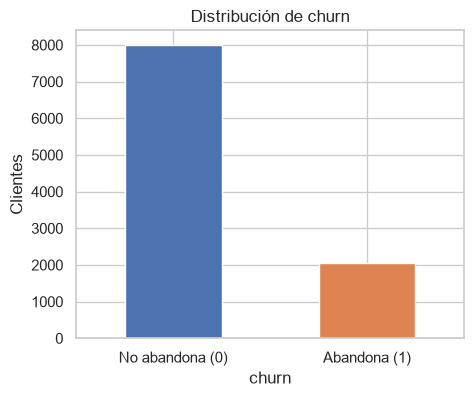

In [9]:
conteo = df["churn"].value_counts()
proporcion = df["churn"].value_counts(normalize=True) * 100
display(pd.DataFrame({"registros": conteo, "%": proporcion.round(2)}))

ax = conteo.plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(5, 4))
ax.set_xticklabels(["No abandona (0)", "Abandona (1)"], rotation=0)
ax.set_title("Distribución de churn")
ax.set_ylabel("Clientes")
plt.show()

> **¿Qué proporción de clientes abandona?**
>
> El 20,4 %. El 79,6 % se queda, unos 4 a 1.
>
> **¿Qué implica el desbalance?**
>
> Un modelo que siempre diga "no abandona" tiene ~80 % de exactitud sin detectar a nadie, así que se evalúa con recall, precisión y F1. Al entrenar se divide estratificado y se prueba class_weight = "balanced". Además el banco del enunciado tiene 15 % de abandono, menos que el dataset, así que su precisión real será menor.

<a id='s1-5'></a>
## 1.5 Indicadores importantes: calidad de datos

> Esta sección responde:
> - ¿Qué problemas de calidad tienen los datos?

In [10]:
# Unicidad
df.duplicated().sum()            # cantidad de filas repetidas

np.int64(45)

In [11]:
df[df.duplicated(keep=False)]    # muestra todas las copias de cada fila repetida

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
60,678.0,France,Male,40.0,1,0.00,2,1,1,187343.40,0
207,813.0,France,Female,62.0,10,64667.95,2,0,1,140454.14,0
407,756.0,Germany,Male,44.0,10,137452.09,1,1,0,189543.90,0
439,736.0,Spain,Male,32.0,7,0.00,1,0,1,79082.62,0
560,678.0,France,Male,40.0,1,0.00,2,1,1,187343.40,0
...,...,...,...,...,...,...,...,...,...,...,...
9547,724.0,France,Male,34.0,2,154485.74,2,0,0,78560.64,0
9706,615.0,Germany,Male,24.0,8,108528.07,2,0,0,179488.41,1
9709,678.0,France,Male,54.0,7,128914.97,1,0,0,191746.23,1
9757,610.0,France,Female,31.0,6,107784.65,1,1,1,141137.53,0


In [12]:
# Completitud
df.isna().sum()            # cantidad de nulos por columna

credit_score        250
country               0
gender                0
age                 300
tenure                0
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    350
churn                 0
dtype: int64

In [13]:
# Consistencia
df["country"].value_counts()

country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64

In [14]:
df["gender"].value_counts()

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64

In [15]:
# Validez: dropna() para que los nulos no cuenten como fuera de rango
pd.Series({
    "credit_score": (~df["credit_score"].dropna().between(300, 850)).sum(),   # fuera del rango [minimo, maximo]
    "age": (~df["age"].dropna().between(18, 100)).sum(),
    "tenure": (~df["tenure"].between(0, 10)).sum(),
    "products_number": (~df["products_number"].between(1, 4)).sum(),
    "balance": (df["balance"] < 0).sum(),                                    # valores negativos
    "estimated_salary": (df["estimated_salary"] < 0).sum(),
}, name="fuera de rango")

credit_score        4
age                 6
tenure              3
products_number     0
balance             0
estimated_salary    3
Name: fuera de rango, dtype: int64

> **¿Qué problemas de calidad tienen los datos?**
>
> - Unicidad: 45 registros repetidos.
> - Completitud: nulos en credit_score (250), age (300), balance (200) y estimated_salary (350), todos por debajo del 5 %.
> - Consistencia: country tiene 9 escrituras para 3 países y gender usa M y F además de Male y Female.
> - Validez: 16 valores fuera del rango del diccionario: credit_score (4), age (6), tenure (3) y estimated_salary (3).

<a id='s1-6'></a>
## 1.6 Preparación de los datos

> Esta sección responde:
> - ¿Cómo se corrigieron los problemas de calidad?

<a id='s1-6-1'></a>
### 1.6.1 Duplicados

> Esta sección responde:
> - ¿Cuántos registros quedan sin duplicados?

In [16]:
df = df.drop_duplicates().reset_index(drop=True)
len(df)                          # registros que quedan

10000

> **¿Cuántos registros quedan sin duplicados?**
>
> 10.000.

<a id='s1-6-2'></a>
### 1.6.2 Valores inválidos

> Esta sección responde:
> - ¿Qué se hizo con los valores inválidos?
> - ¿Cómo se unificaron las categorías?

In [17]:
df.describe().loc[["min", "max"]].T

,min,max
credit_score,95.0,1200.00
age,-1.0,210.00
tenure,-2.0,25.00
balance,0.0,250898.09
products_number,1.0,4.00
credit_card,0.0,1.00
active_member,0.0,1.00
estimated_salary,-5000.0,199992.48
churn,0.0,1.00


In [18]:
pd.Series({
    "credit_score": (~df["credit_score"].dropna().between(300, 850)).sum(),   # fuera del rango [minimo, maximo]
    "age": (~df["age"].dropna().between(18, 100)).sum(),
    "tenure": (~df["tenure"].between(0, 10)).sum(),
    "estimated_salary": (df["estimated_salary"] < 0).sum(),                  # valores negativos
}, name="valores a recortar")

credit_score        4
age                 6
tenure              3
estimated_salary    3
Name: valores a recortar, dtype: int64

In [19]:
df["age"] = df["age"].clip(lower=18, upper=100)       # límites inferior y superior
df["credit_score"] = df["credit_score"].clip(lower=300, upper=850)
df["tenure"] = df["tenure"].clip(lower=0, upper=10)
df["estimated_salary"] = df["estimated_salary"].clip(lower=0)       # solo límite inferior

In [20]:
df.describe().loc[["min", "max"]].T      # rangos después del recorte

,min,max
credit_score,300.0,850.00
age,18.0,100.00
tenure,0.0,10.00
balance,0.0,250898.09
products_number,1.0,4.00
credit_card,0.0,1.00
active_member,0.0,1.00
estimated_salary,0.0,199992.48
churn,0.0,1.00


In [21]:
# Unificar la escritura de country y gender
df["country"] = df["country"].str.strip().str.title()    # sin espacios y con mayúscula inicial
df["country"].value_counts()

country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [22]:
df["gender"] = df["gender"].replace({"M": "Male", "F": "Female"})   # unificar variantes
df["gender"].value_counts()

gender
Male      5457
Female    4543
Name: count, dtype: int64

> **¿Qué se hizo con los valores inválidos?**
>
> Se recortaron los 16 al rango del diccionario. Un valor muy lejano, como age = 210, queda en 100 años; marcarlo como nulo sería más fiel, pero son solo 16 registros (0,16 %) y casi no cambian las distribuciones.
>
> **¿Cómo se unificaron las categorías?**
>
> country queda con France, Germany y Spain, y gender con Male y Female.

<a id='s1-6-3'></a>
### 1.6.3 Outliers

> Esta sección responde:
> - ¿Qué variables tienen atípicos?
> - ¿Cómo se trataron?

In [23]:
q1, q3 = df["age"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["age"] < inferior) | (df["age"] > superior)).sum()

np.int64(347)

In [24]:
q1, q3 = df["credit_score"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["credit_score"] < inferior) | (df["credit_score"] > superior)).sum()

np.int64(14)

In [25]:
q1, q3 = df["tenure"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["tenure"] < inferior) | (df["tenure"] > superior)).sum()

np.int64(0)

In [26]:
q1, q3 = df["estimated_salary"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["estimated_salary"] < inferior) | (df["estimated_salary"] > superior)).sum()

np.int64(0)

In [27]:
q1, q3 = df["balance"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["balance"] < inferior) | (df["balance"] > superior)).sum()

np.int64(0)

<a id='s1-6-3-clip'></a>
#### Recorte de atípicos (percentiles 1 y 99)

In [28]:
inferior, superior = df["age"].quantile([0.01, 0.99])   # percentiles 1 y 99
df["age_clip"] = df["age"].clip(lower=inferior, upper=superior)

In [29]:
inferior, superior = df["credit_score"].quantile([0.01, 0.99])   # percentiles 1 y 99
df["credit_score_clip"] = df["credit_score"].clip(lower=inferior, upper=superior)

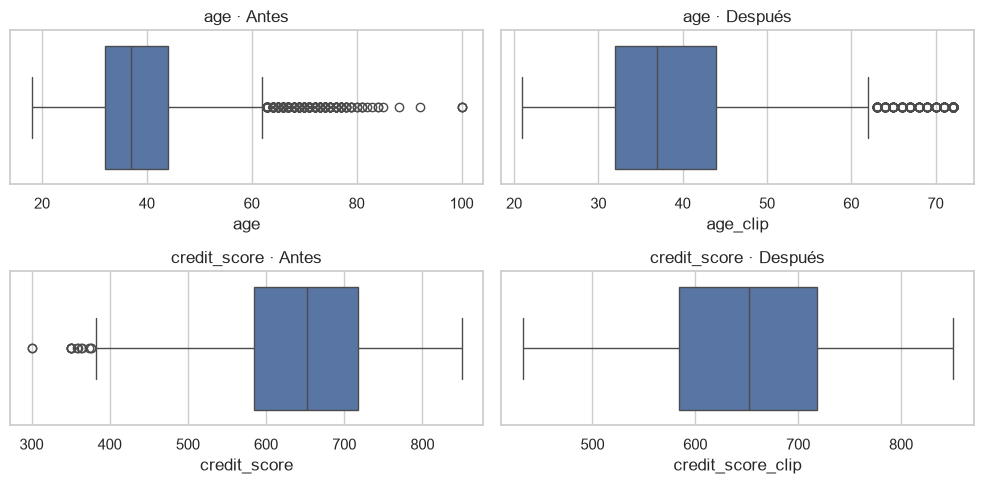

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for i, col in enumerate(["age", "credit_score"]):
    sns.boxplot(x=df[col], ax=axes[i, 0]).set_title(f"{col} · Antes")
    sns.boxplot(x=df[f"{col}_clip"], ax=axes[i, 1]).set_title(f"{col} · Después")
plt.tight_layout()
plt.show()

In [31]:
df[["age", "age_clip", "credit_score", "credit_score_clip"]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,9700.0,38.930103,10.530092,18.0,32.0,37.0,44.0,100.0
age_clip,9700.0,38.901443,10.329442,21.0,32.0,37.0,44.0,72.0
credit_score,9750.0,650.593026,96.768001,300.0,584.0,652.0,718.0,850.0
credit_score_clip,9750.0,650.817231,96.195754,432.0,584.0,652.0,718.0,850.0


> **¿Qué variables tienen atípicos?**
>
> Por IQR, solo age (347, clientes mayores de 62 años) y credit_score (14, puntajes bajos).
>
> **¿Cómo se trataron?**
>
> Se recortaron a los percentiles 1 y 99 en columnas nuevas: age_clip queda entre 21 y 72 años y credit_score_clip entre 432 y 850. La media y los cuartiles casi no cambian. El modelo usa estas columnas.

<a id='s1-6-4'></a>
### 1.6.4 Valores nulos

> Esta sección responde:
> - ¿Cómo se tratan los nulos?

In [32]:
(df.isna().mean() * 100).round(2)     # porcentaje de nulos por columna

credit_score         2.5
country              0.0
gender               0.0
age                  3.0
tenure               0.0
balance              2.0
products_number      0.0
credit_card          0.0
active_member        0.0
estimated_salary     3.5
churn                0.0
age_clip             3.0
credit_score_clip    2.5
dtype: float64

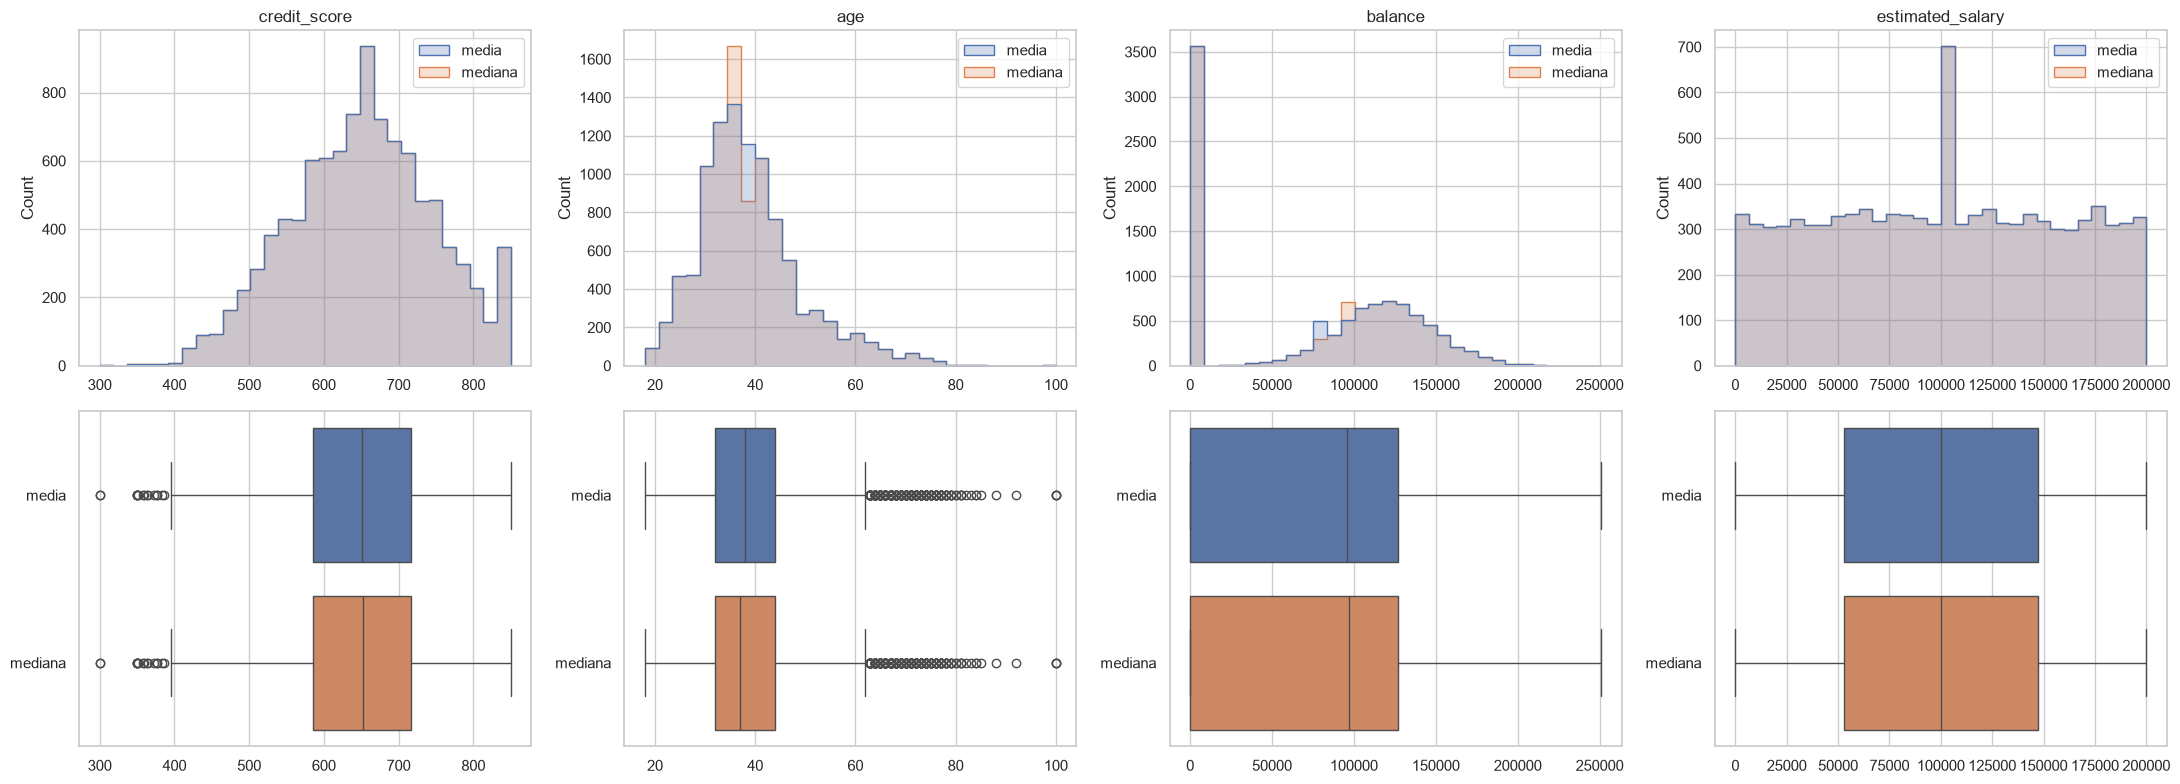

In [33]:
# Solo para comparar media y mediana: no se modifica df
con_nulos = ["credit_score", "age", "balance", "estimated_salary"]

fig, axes = plt.subplots(2, len(con_nulos), figsize=(22, 8))
for i, col in enumerate(con_nulos):
    imputado = pd.DataFrame({
        "media": df[col].fillna(df[col].mean()),        # media
        "mediana": df[col].fillna(df[col].median()),    # mediana
    })
    sns.histplot(imputado, bins=30, element="step", ax=axes[0, i])
    axes[0, i].set_title(col)
    sns.boxplot(data=imputado, orient="h", ax=axes[1, i])
plt.tight_layout()
plt.show()

> **¿Cómo se tratan los nulos?**
>
> Ninguna columna pasa del 5 % de nulos (el máximo es 3,5 % en estimated_salary), así que se imputan. Se elige la mediana: en balance la media (~76.000) cae entre el pico de ceros y la campana, donde casi no hay clientes, y en age la media se corre por el sesgo. La imputación se hace en 2.1, solo con entrenamiento.

<a id='s1-7'></a>
## 1.7 Selección de variables y codificación

> Esta sección responde:
> - ¿Qué variables continuas se relacionan con el abandono?
> - ¿Qué variables categóricas se relacionan con el abandono?
> - ¿Qué variables se usan en el modelo y cómo se codifican?

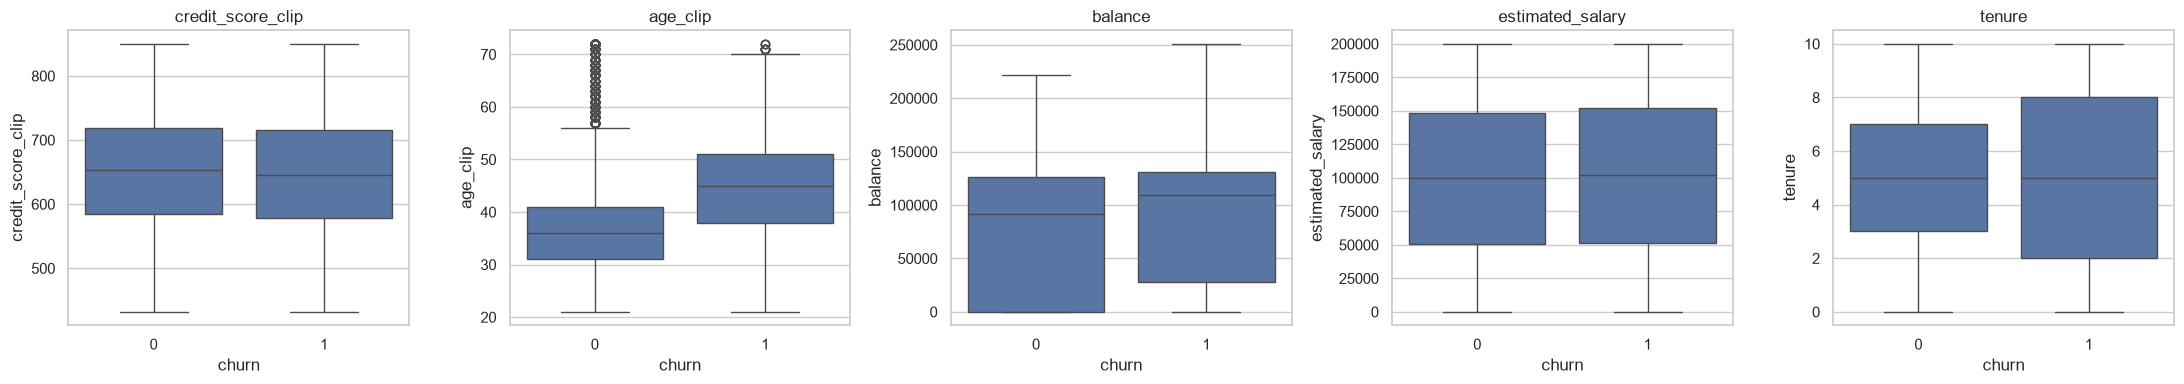

In [34]:
# Variables continuas por clase
columnas_continuas = ["credit_score_clip", "age_clip", "balance", "estimated_salary", "tenure"]

fig, axes = plt.subplots(1, len(columnas_continuas), figsize=(22, 4))
for ax, columna in zip(axes, columnas_continuas):
    sns.boxplot(x="churn", y=columna, data=df, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

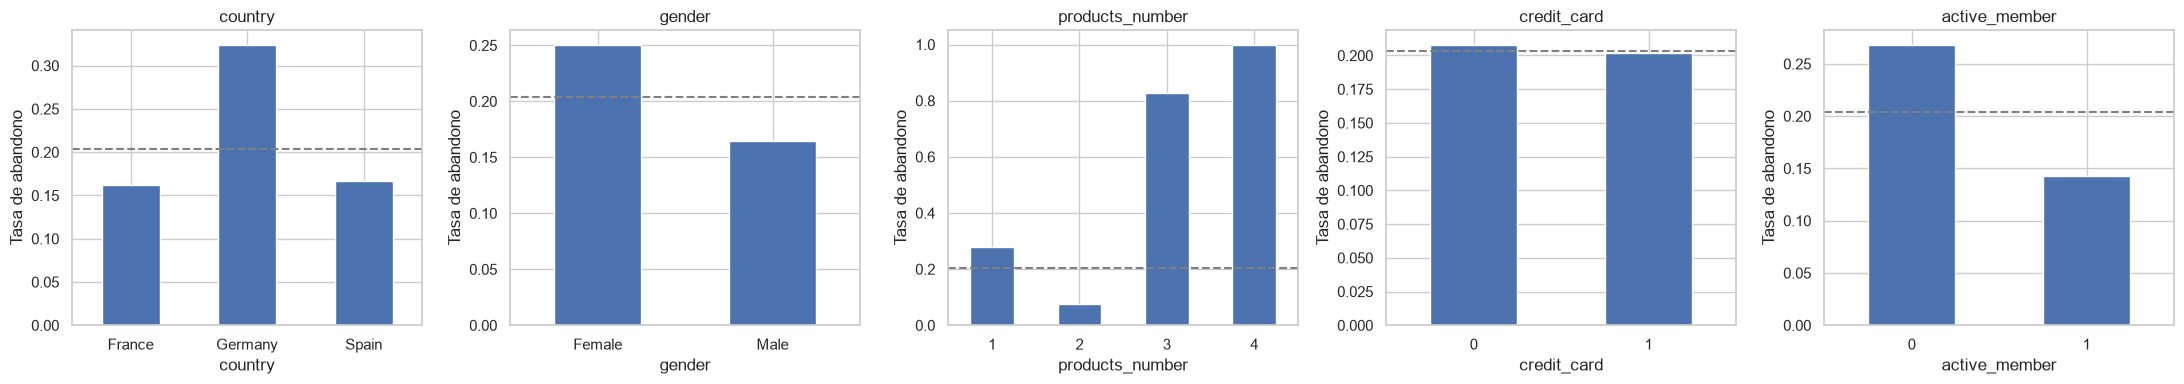

In [35]:
# Tasa de abandono por categoría; la línea punteada es la tasa global (20,4 %)
columnas_categoricas = ["country", "gender", "products_number", "credit_card", "active_member"]

fig, axes = plt.subplots(1, len(columnas_categoricas), figsize=(22, 4))
for ax, columna in zip(axes, columnas_categoricas):
    proporcion = df.groupby(columna)["churn"].mean()
    proporcion.plot(kind="bar", ax=ax)
    ax.axhline(df["churn"].mean(), color="gray", linestyle="--")   # tasa global
    ax.set_title(columna)
    ax.set_ylabel("Tasa de abandono")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [36]:
# Prueba t y prueba U de Mann-Whitney (la U porque age_clip está sesgada y balance tiene el pico en cero)
from scipy import stats

resultados = []
for columna in columnas_continuas:
    grupo_1 = df.loc[df["churn"] == 1, columna].dropna()
    grupo_0 = df.loc[df["churn"] == 0, columna].dropna()
    estadistico, p_valor = stats.ttest_ind(grupo_1, grupo_0, equal_var=False)
    resultados.append({
        "variable": columna,
        "media_clase_1": grupo_1.mean(),
        "media_clase_0": grupo_0.mean(),
        "diferencia_medias": grupo_1.mean() - grupo_0.mean(),
        "t": estadistico,
        "p_valor": p_valor,
    })

tabla_t = pd.DataFrame(resultados).sort_values("p_valor")
tabla_t["significativa"] = tabla_t["p_valor"] < 0.05
tabla_t

,variable,media_clase_1,media_clase_0,diferencia_medias,t,p_valor,significativa
1,age_clip,44.751259,37.395385,7.355874,29.856237,1.484029e-172,True
2,balance,90774.560290,72564.297095,18210.263195,12.247968,9.235238e-34,True
0,credit_score_clip,645.966616,652.050946,-6.084329,-2.471494,1.351013e-02,True
4,tenure,4.932744,5.035163,-0.102418,-1.410183,1.585856e-01,False
3,estimated_salary,101248.955526,99728.281111,1520.674415,1.039052,2.988634e-01,False


In [37]:
resultados = []
for columna in columnas_continuas:
    grupo_1 = df.loc[df["churn"] == 1, columna].dropna()
    grupo_0 = df.loc[df["churn"] == 0, columna].dropna()
    estadistico, p_valor = stats.mannwhitneyu(grupo_1, grupo_0, alternative="two-sided")
    resultados.append({
        "variable": columna,
        "mediana_clase_1": grupo_1.median(),
        "mediana_clase_0": grupo_0.median(),
        "diferencia_medianas": grupo_1.median() - grupo_0.median(),
        "r": 1 - 2 * estadistico / (len(grupo_1) * len(grupo_0)),
        "U": estadistico,
        "p_valor": p_valor,
    })

tabla_u = pd.DataFrame(resultados).sort_values("p_valor")
tabla_u["significativa"] = tabla_u["p_valor"] < 0.05
tabla_u

,variable,mediana_clase_1,mediana_clase_0,diferencia_medianas,r,U,p_valor,significativa
1,age_clip,45.00,36.00,9.00,-0.457618,11165353.0,5.127637e-218,True
2,balance,109153.96,91835.16,17318.80,-0.154023,9011416.5,9.908658e-28,True
0,credit_score_clip,646.00,654.00,-8.00,0.035037,7414403.5,1.599086e-02,True
4,tenure,5.00,5.00,0.00,0.020307,7945621.0,1.546613e-01,False
3,estimated_salary,101954.78,99645.04,2309.74,-0.015225,7677073.0,2.965375e-01,False


In [38]:
# Chi-cuadrado y V de Cramér
resultados = []
for columna in columnas_categoricas:
    tabla = pd.crosstab(df[columna], df["churn"])
    chi2, p_valor, grados_libertad, esperadas = stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    resultados.append({
        "variable": columna,
        "chi2": chi2,
        "p_valor": p_valor,
        "v_cramer": np.sqrt(chi2 / (n * (min(tabla.shape) - 1))),
        "celdas_esperadas_menores_5": int((esperadas < 5).sum()),
    })

tabla_chi = pd.DataFrame(resultados).sort_values("p_valor")
tabla_chi["significativa"] = tabla_chi["p_valor"] < 0.05
tabla_chi

,variable,chi2,p_valor,v_cramer,celdas_esperadas_menores_5,significativa
2,products_number,1503.629362,0.000000e+00,0.387767,0,True
0,country,301.255337,3.830318e-66,0.173567,0,True
4,active_member,242.985342,8.785858e-55,0.155880,0,True
1,gender,112.918571,2.248210e-26,0.106263,0,True
3,credit_card,0.471338,4.923724e-01,0.006865,0,False


In [39]:
seleccionadas = ["age_clip", "balance", "credit_score_clip", "products_number", "country", "active_member", "gender"]

df_modelo = df[seleccionadas + ["churn"]]
df_modelo.shape

(10000, 8)

In [40]:
# One-hot de country, gender y products_number
df_modelo = pd.get_dummies(df_modelo, columns=["country", "gender", "products_number"], drop_first=True, dtype=int)
df_modelo.head()

,age_clip,balance,credit_score_clip,active_member,churn,country_Germany,country_Spain,gender_Male,products_number_2,products_number_3,products_number_4
0,46.0,0.00,432.0,1,1,0,0,0,0,0,0
1,67.0,157094.78,689.0,1,0,1,0,1,0,0,0
2,48.0,129120.64,477.0,1,0,0,1,0,0,0,0
3,35.0,206868.78,573.0,1,0,1,0,0,1,0,0
4,69.0,71996.09,849.0,1,0,0,0,1,0,0,0


> **¿Qué variables continuas se relacionan con el abandono?**
>
> age_clip es la que más separa: los que abandonan tienen ~7 años más (r ≈ -0,46). balance también, con ~18.000 más (r ≈ -0,15). credit_score_clip sale significativa, pero la diferencia es de solo ~6 puntos. estimated_salary y tenure no (p > 0,05). La prueba t y la U coinciden en todas.
>
> **¿Qué variables categóricas se relacionan con el abandono?**
>
> products_number es la más fuerte (V ≈ 0,39): con 2 productos abandona ~8 %, con 1 ~28 % y con 3 o 4 casi todos. En Alemania abandona ~32 %, el doble que en Francia y España. Los inactivos abandonan ~27 % frente a ~14 % de los activos, y las mujeres ~25 % frente a ~17 % de los hombres. credit_card no tiene relación (p ≈ 0,49).
>
> **¿Qué variables se usan en el modelo y cómo se codifican?**
>
> Las significativas (p < 0,05): age_clip, balance, credit_score_clip, products_number, country, active_member y gender. Se descartan estimated_salary, tenure y credit_card. country, gender y products_number van en one-hot con drop_first, así que la referencia es France, Female y 1 producto. products_number va como categórica porque su efecto no es ordenado. df_modelo queda con 10.000 registros y 10 variables.

<a id='s2'></a>
# 2. Entrenamiento del Modelo de Machine Learning

Las pruebas de la práctica (árbol, KNN, ensambles y redes) están en Taller2_Modelos.ipynb. Aquí se entrenan los dos modelos del taller: regresión logística y Random Forest.

<a id='s2-1'></a>
## 2.1 División de los datos

> Esta sección responde:
> - ¿Cómo se dividieron los datos?
> - ¿Cómo se trataron los nulos y la escala de las variables?

In [41]:
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns="churn")
y = df_modelo["churn"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

pd.DataFrame({
    "registros": [len(y_train), len(y_val), len(y_test)],
    "% abandono": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["entrenamiento", "validación", "prueba"]).round(2)

,registros,% abandono
entrenamiento,6000,20.38
validación,2000,20.35
prueba,2000,20.35


In [42]:
medianas = X_train[["age_clip", "balance", "credit_score_clip"]].median()   # solo con entrenamiento

X_train = X_train.fillna(medianas)
X_val = X_val.fillna(medianas)
X_test = X_test.fillna(medianas)

print(medianas)
print("Nulos después de imputar:", X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

age_clip                37.00
balance              96007.24
credit_score_clip      652.00
dtype: float64
Nulos después de imputar: 0 0 0


In [43]:
# Conjuntos que usa Taller2_Modelos.ipynb
pd.concat([X_train, y_train], axis=1).to_csv("churn_train.csv", index=False)
pd.concat([X_val, y_val], axis=1).to_csv("churn_val.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv("churn_test.csv", index=False)

In [44]:
from sklearn.preprocessing import StandardScaler

continuas_modelo = ["age_clip", "balance", "credit_score_clip"]
escalador = StandardScaler()

X_train_esc = X_train.copy()
X_val_esc = X_val.copy()
X_test_esc = X_test.copy()
X_train_esc[continuas_modelo] = escalador.fit_transform(X_train[continuas_modelo])   # solo con entrenamiento
X_val_esc[continuas_modelo] = escalador.transform(X_val[continuas_modelo])
X_test_esc[continuas_modelo] = escalador.transform(X_test[continuas_modelo])

X_train_esc[continuas_modelo].describe().loc[["mean", "std"]].round(2)

,age_clip,balance,credit_score_clip
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


In [45]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # 5 folds estratificados

> **¿Cómo se dividieron los datos?**
>
> 60 % entrenamiento, 20 % validación y 20 % prueba, estratificado para que los tres tengan ~20,4 % de abandono.
>
> **¿Cómo se trataron los nulos y la escala de las variables?**
>
> Los nulos se imputan con la mediana y las continuas se estandarizan con StandardScaler. Las dos cosas se calculan solo con entrenamiento, para que validación y prueba no influyan en el modelo.

<a id='s2-2'></a>
## 2.2 Modelo A: Regresión logística

> Esta sección responde:
> - ¿Qué hiperparámetros se probaron y cuál fue la mejor combinación?

In [46]:
from sklearn.linear_model import LogisticRegression

param_grid = {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}
busqueda_logistica = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_logistica.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_logistica.best_params_)
print("F1 de validación cruzada:", round(busqueda_logistica.best_score_, 3))

Mejor combinación: {'C': 1, 'class_weight': 'balanced'}
F1 de validación cruzada: 0.567


In [47]:
resultados_logistica = pd.DataFrame(busqueda_logistica.cv_results_)[["param_C", "param_class_weight", "mean_test_score"]]
resultados_logistica.sort_values("mean_test_score", ascending=False).round(3)

,param_C,param_class_weight,mean_test_score
5,1.00,balanced,0.567
7,10.00,balanced,0.566
3,0.10,balanced,0.563
1,0.01,balanced,0.546
6,10.00,None,0.509
4,1.00,None,0.508
2,0.10,None,0.484
0,0.01,None,0.307


> **¿Qué hiperparámetros se probaron y cuál fue la mejor combinación?**
>
> C y class_weight, con GridSearchCV de 5 folds optimizando F1. La mejor es C = 1 con class_weight = "balanced" (F1 0,567). Sin pesos el mejor F1 es 0,509.

<a id='s2-3'></a>
## 2.3 Modelo B: Random Forest

> Esta sección responde:
> - ¿Qué hiperparámetros se probaron y cuál fue la mejor combinación?

In [48]:
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced"],
}
busqueda_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_rf.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_rf.best_params_)
print("F1 de validación cruzada:", round(busqueda_rf.best_score_, 3))

Mejor combinación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 400}
F1 de validación cruzada: 0.616


In [49]:
resultados_rf = pd.DataFrame(busqueda_rf.cv_results_)[
    ["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_class_weight", "mean_test_score"]
]
resultados_rf.sort_values("mean_test_score", ascending=False).round(3).head(8)   # 8 mejores de 36 combinaciones

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score
27,400,10,5,balanced,0.616
24,200,10,1,balanced,0.614
25,400,10,1,balanced,0.614
33,400,None,5,balanced,0.613
26,200,10,5,balanced,0.613
32,200,None,5,balanced,0.612
31,400,None,1,balanced,0.610
30,200,None,1,balanced,0.610


> **¿Qué hiperparámetros se probaron y cuál fue la mejor combinación?**
>
> Número de árboles, profundidad máxima, mínimo de registros por hoja y class_weight. La mejor es 400 árboles, max_depth = 10, min_samples_leaf = 5 y class_weight = "balanced" (F1 0,616). Las ocho mejores usan "balanced" y quedan entre 0,610 y 0,616, así que los demás valores casi no cambian el resultado.

<a id='s3'></a>
# 3. Análisis Cuantitativo de Resultados del Modelo

> Esta sección responde:
> - ¿Qué tan bien predicen los modelos y cuál se elige?

<a id='s3-1'></a>
## 3.1 Métricas de evaluación

> Referencia: [P2 · A3 paso 5](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/)

> Esta sección responde:
> - ¿Cuántos abandonos detecta cada modelo y cuántas falsas alarmas genera?
> - ¿Cuánto cambian las métricas entre entrenamiento y validación?

0 = el cliente se queda, 1 = el cliente abandona.

In [50]:
from sklearn.metrics import f1_score

modelos = {
    "Regresión logística": busqueda_logistica.best_estimator_,
    "Random Forest": busqueda_rf.best_estimator_,
}

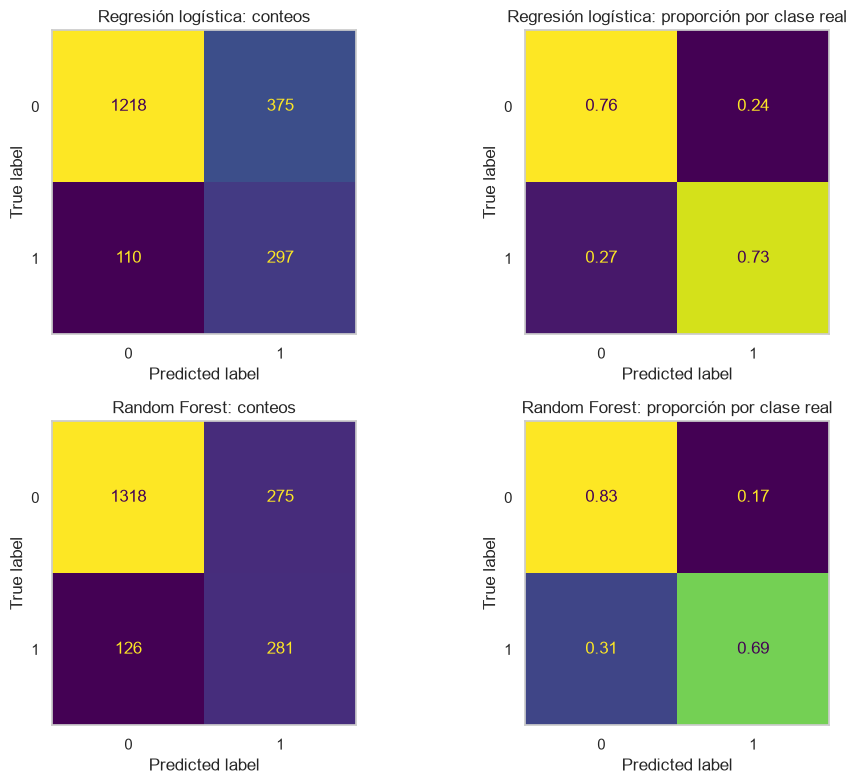

In [51]:
from sklearn.metrics import ConfusionMatrixDisplay

# Filas: modelos. Columnas: conteos y proporción por clase real (validación)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for fila, (nombre, modelo) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_val_esc, y_val, ax=fila[0], colorbar=False)
    fila[0].set_title(f"{nombre}: conteos")
    ConfusionMatrixDisplay.from_estimator(modelo, X_val_esc, y_val, normalize="true", ax=fila[1], colorbar=False) # normalizamos para saber si hay problemas de desbalnace de clases 
    fila[1].set_title(f"{nombre}: proporción por clase real")
for ax in axes.ravel():
    ax.grid(False)
plt.tight_layout()
plt.show()

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score


linea_base = y_val.value_counts(normalize=True).max()

print(f"Exactitud de un modelo que siempre dice 'no abandona': {linea_base:.3f}")


# Métricas con umbral 0,5 en entrenamiento y validación
filas = []
for conjunto, X, y in [("entrenamiento", X_train_esc, y_train), ("validación", X_val_esc, y_val)]:
    for nombre, modelo in modelos.items():
        y_pred = modelo.predict(X)
        filas.append({
            "modelo": nombre,
            "conjunto": conjunto,
            "exactitud": accuracy_score(y, y_pred),
            "precisión": precision_score(y, y_pred),
            "recall": recall_score(y, y_pred),
            "F1": f1_score(y, y_pred),
        })
pd.DataFrame(filas).set_index(["modelo", "conjunto"]).round(3)

Exactitud de un modelo que siempre dice 'no abandona': 0.796


,,exactitud,precisión,recall,F1
modelo,conjunto,,,,
Regresión logística,entrenamiento,0.764,0.452,0.748,0.563
Random Forest,entrenamiento,0.856,0.602,0.858,0.708
Regresión logística,validación,0.758,0.442,0.730,0.551
Random Forest,validación,0.800,0.505,0.690,0.584


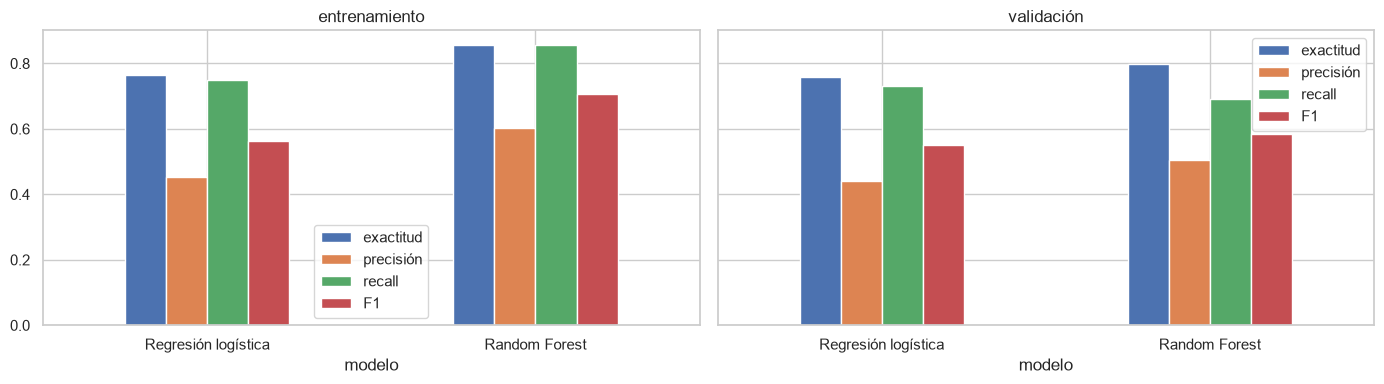

In [53]:
def graficar_metricas(tabla):
    nombres = tabla["conjunto"].unique()
    fig, axes = plt.subplots(1, len(nombres), figsize=(7 * len(nombres), 4), sharey=True, squeeze=False)
    for ax, titulo in zip(axes[0], nombres):
        tabla[tabla["conjunto"] == titulo].set_index("modelo")[["exactitud", "precisión", "recall", "F1"]].plot(kind="bar", ax=ax, rot=0)
        ax.set_title(titulo)
    plt.tight_layout()
    plt.show()


graficar_metricas(pd.DataFrame(filas))

> **¿Cuántos abandonos detecta cada modelo y cuántas falsas alarmas genera?**
>
> - Regresión logística: detecta 297 de 407 (73 %) con 375 falsas alarmas.
> - Random Forest: detecta 281 de 407 (69 %) con 275 falsas alarmas.
>
> **¿Cuánto cambian las métricas entre entrenamiento y validación?**
>
> Random Forest es el que más cambia: su F1 baja de 0,708 a 0,584. Memoriza más, pero sigue siendo mejor en validación que la logística, que casi no cambia (0,563 a 0,551).

<a id='s3-2'></a>
## 3.2 Curvas precisión-recall y ROC

> Referencia: [P2 · A3 pasos 6 y 7](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/)

> Esta sección responde:
> - ¿Qué modelo tiene mejor AP y AUC en validación?
> - ¿Dónde está la línea base de la curva precisión-recall?
> - ¿Por qué la curva ROC se ve más optimista que la de precisión-recall?

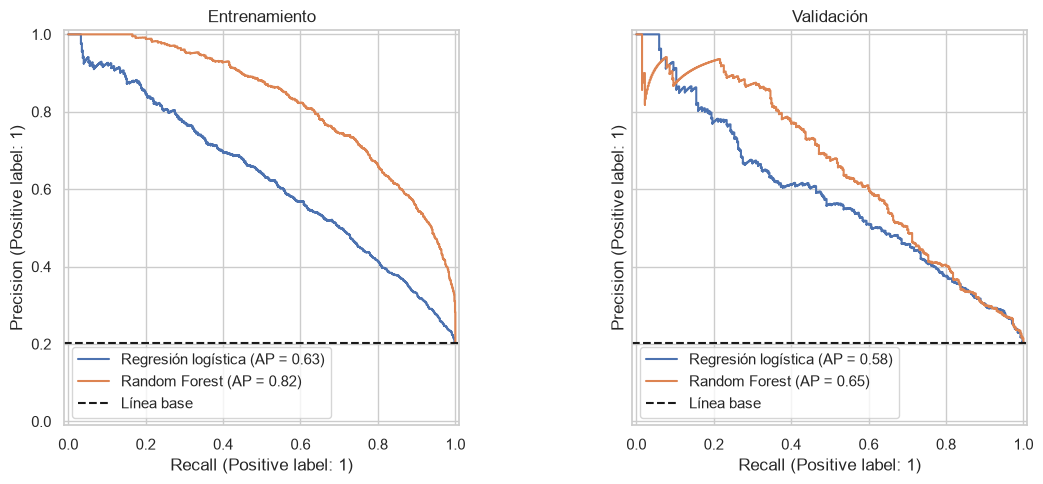

In [54]:
from sklearn.metrics import PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
conjuntos = [("Entrenamiento", X_train_esc, y_train), ("Validación", X_val_esc, y_val)]

for ax, (titulo, X, y) in zip(axes, conjuntos):
    for nombre, modelo in modelos.items():
        PrecisionRecallDisplay.from_estimator(modelo, X, y, ax=ax, name=nombre)
    ax.axhline((y == 1).mean(), color="k", linestyle="--", label="Línea base")
    ax.set_title(titulo)
    ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

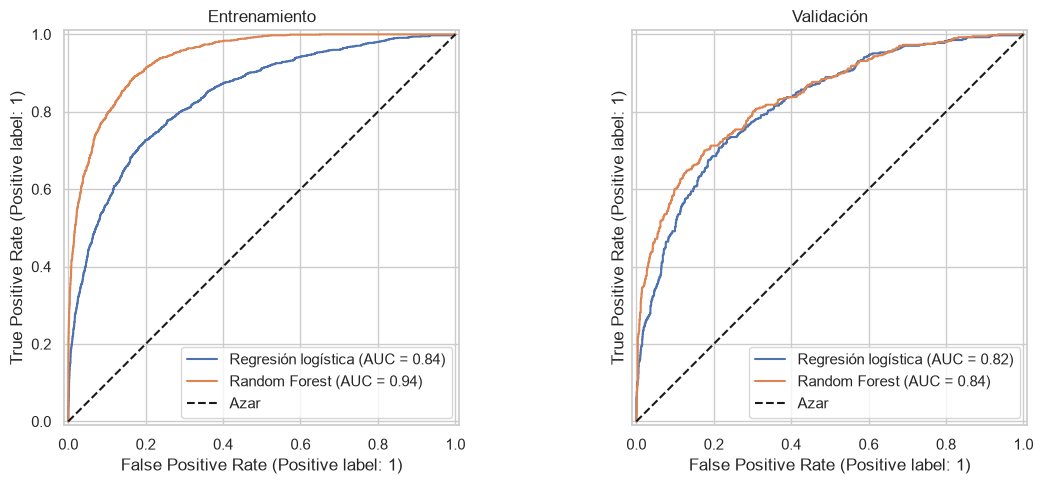

In [55]:
from sklearn.metrics import RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
conjuntos = [("Entrenamiento", X_train_esc, y_train), ("Validación", X_val_esc, y_val)]

for ax, (titulo, X, y) in zip(axes, conjuntos):
    for nombre, modelo in modelos.items():
        RocCurveDisplay.from_estimator(modelo, X, y, ax=ax, name=nombre)
    ax.plot([0, 1], [0, 1], "k--", label="Azar")
    ax.set_title(titulo)
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

> **¿Qué modelo tiene mejor AP y AUC en validación?**
>
> Random Forest en las dos: AP 0,65 frente a 0,58 y AUC 0,84 frente a 0,82. En AUC la diferencia es muy pequeña.
>
> **¿Dónde está la línea base de la curva precisión-recall?**
>
> En 0,20, la proporción de clientes que abandonan. Es la precisión de un modelo que marca a todos como "se va".
>
> **¿Por qué la curva ROC se ve más optimista que la de precisión-recall?**
>
> Las dos miden las falsas alarmas, pero contra grupos distintos: la ROC las divide entre todos los que se quedan y la precisión las compara con los aciertos. Con clases desbalanceadas, la de precisión-recall muestra mejor el problema.

<a id='s3-3'></a>
## 3.3 Significado de las métricas para la empresa

> Referencia: [P2 · A3 paso 10](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/)

> Esta sección responde:
> - ¿Qué significan el recall, la precisión y el F1 para la campaña de retención del banco?

> **¿Qué significan el recall, la precisión y el F1 para la campaña de retención del banco?**
>
> - Recall: cuántos de los que se iban a ir alcanza la campaña. Random Forest llega a 281 de 407 (69 %).
> - Precisión: cuántos de los contactados sí se iban a ir. Es 0,51, así que la mitad de los contactos se gasta en clientes que se iban a quedar.
> - F1: resume las dos (0,584) y las pesa igual. Para el banco pesa más el recall, porque un cliente perdido vale entre 500.000 y 900.000 pesos al año y un contacto mucho menos.

<a id='s3-4'></a>
## 3.4 Justificación del modelo

> Esta sección responde:
> - ¿Qué modelo se elige y se mantiene en prueba?
> - ¿La diferencia entre Random Forest y la logística es significativa?

<a id='s3-4-1'></a>
### 3.4.1 Elección en validación

> Referencia: [P2 · A3 paso 8](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/) · [P2 · A4 paso 9](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-4/)

> Esta sección responde:
> - ¿Qué modelo se elige?
> - ¿Cambiaría la elección si para el banco fuera más costoso no detectar a un cliente que abandona que contactar a uno que no iba a abandonar?

Modelos probados en la práctica. Los valores vienen de Taller2_Modelos.ipynb, que se corrió en otro equipo; por eso Random Forest aparece con 0,585 y aquí con 0,584.

| Actividad | Modelo | F1 entrenamiento | F1 validación |
|---|---|---|---|
| 3 | Regresión logística | 0,563 | 0,551 |
| 3 | Árbol de decisión | 0,620 | 0,556 |
| 3 | KNN | 1,000 | 0,503 |
| 4 | Random Forest | 0,710 | 0,585 |
| 4 | Gradient Boosting | 0,646 | 0,575 |
| 4 | Votación suave | 0,892 | 0,585 |
| 4 | Stacking | 0,738 | 0,569 |
| 5 | Red neuronal (32-16-8) | 0,624 | 0,559 |

In [56]:
from sklearn.metrics import roc_auc_score, average_precision_score

filas = []
for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_val_esc)
    y_prob = modelo.predict_proba(X_val_esc)[:, 1]
    filas.append({
        "modelo": nombre,
        "exactitud": accuracy_score(y_val, y_pred),
        "precisión": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "AUC": roc_auc_score(y_val, y_prob),
        "AP": average_precision_score(y_val, y_prob),
        "diferencia F1 (entrenamiento - validación)": f1_score(y_train, modelo.predict(X_train_esc)) - f1_score(y_val, y_pred),
    })
pd.DataFrame(filas).set_index("modelo").round(3)

,exactitud,precisión,recall,F1,AUC,AP,diferencia F1 (entrenamiento - validación)
modelo,,,,,,,
Regresión logística,0.758,0.442,0.73,0.551,0.818,0.583,0.013
Random Forest,0.800,0.505,0.69,0.584,0.837,0.652,0.124


> **¿Qué modelo se elige?**
>
> Random Forest. Tiene el mayor F1 en validación (0,584 frente a 0,551) y gana en exactitud, precisión, AUC y AP. La logística solo gana en recall (0,730 frente a 0,690). Sobreajusta más, pero igual es el mejor en validación. La logística queda como referencia porque es más fácil de interpretar.
>
> **¿Cambiaría la elección si para el banco fuera más costoso no detectar a un cliente que abandona?**
>
> Podría cambiar. En ese caso pesa más el recall, y ahí gana la logística: detecta 16 abandonos más a cambio de 116 contactos más. Con un ingreso de 700.000 pesos al año y 30 % de éxito de la campaña, la logística conviene si cada contacto cuesta menos de unos 29.000 pesos. Otra opción es quedarse con Random Forest y bajarle el umbral.

<a id='s3-4-2'></a>
### 3.4.2 Evaluación en prueba

> Referencia: [P2 · A3 paso 9](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/) · [P2 · A4 paso 10](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-4/)

> Esta sección responde:
> - ¿Las métricas se mantienen en prueba?
> - ¿Cuánto mejora el modelo frente a la línea base?
> - ¿Por qué la exactitud sola no es suficiente con desbalance de clases?

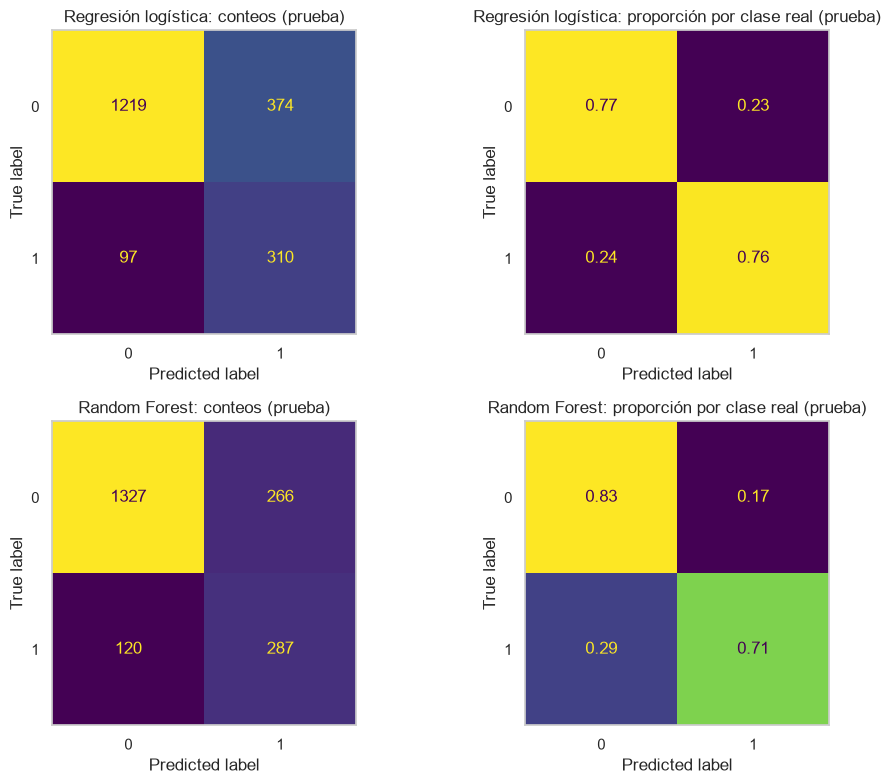

In [57]:
# a) Matriz de confusión en prueba
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for fila, (nombre, modelo) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test_esc, y_test, ax=fila[0], colorbar=False)
    fila[0].set_title(f"{nombre}: conteos (prueba)")
    ConfusionMatrixDisplay.from_estimator(modelo, X_test_esc, y_test, normalize="true", ax=fila[1], colorbar=False)
    fila[1].set_title(f"{nombre}: proporción por clase real (prueba)")
for ax in axes.ravel():
    ax.grid(False)
plt.tight_layout()
plt.show()

In [58]:
# b) Métricas en validación y prueba
filas = []
for nombre, modelo in modelos.items():
    for conjunto, X, y in [("validación", X_val_esc, y_val), ("prueba", X_test_esc, y_test)]:
        y_pred = modelo.predict(X)
        filas.append({
            "modelo": nombre,
            "conjunto": conjunto,
            "exactitud": accuracy_score(y, y_pred),
            "precisión": precision_score(y, y_pred),
            "recall": recall_score(y, y_pred),
            "F1": f1_score(y, y_pred),
        })
pd.DataFrame(filas).set_index(["modelo", "conjunto"]).round(3)

exactitud  precisión  recall     F1
modelo              conjunto                                       
Regresión logística validación      0.758      0.442   0.730  0.551
                    prueba          0.764      0.453   0.762  0.568
Random Forest       validación      0.800      0.505   0.690  0.584
                    prueba          0.807      0.519   0.705  0.598

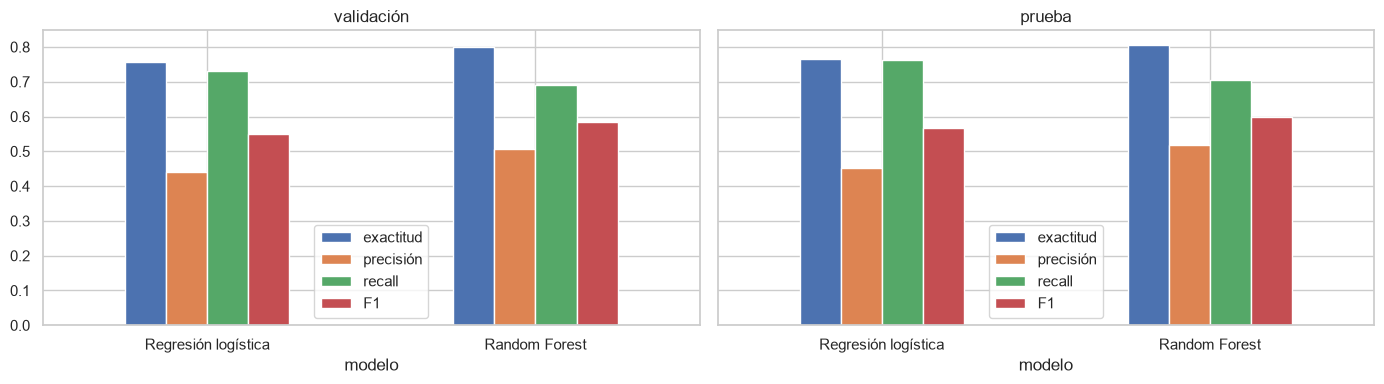

In [59]:
graficar_metricas(pd.DataFrame(filas))

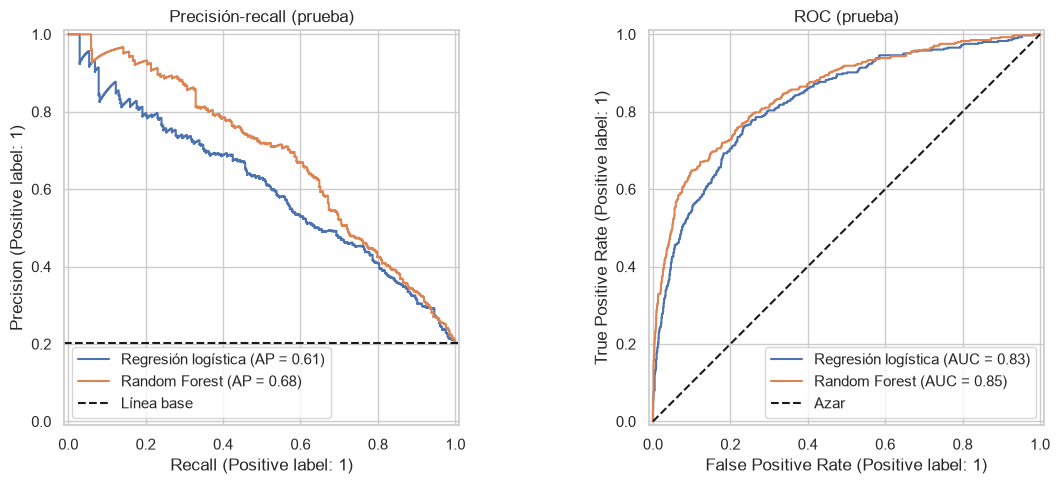

In [60]:
# c) Curvas precisión-recall y ROC en prueba
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for nombre, modelo in modelos.items():
    PrecisionRecallDisplay.from_estimator(modelo, X_test_esc, y_test, ax=axes[0], name=nombre)
    RocCurveDisplay.from_estimator(modelo, X_test_esc, y_test, ax=axes[1], name=nombre)
axes[0].axhline(y_test.mean(), color="k", linestyle="--", label="Línea base")
axes[0].set_title("Precisión-recall (prueba)")
axes[0].legend(loc="lower left")
axes[1].plot([0, 1], [0, 1], "k--", label="Azar")
axes[1].set_title("ROC (prueba)")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [61]:
# d) Modelo que siempre predice que el cliente no abandona
y_base = np.zeros(len(y_test), dtype=int)
print("Exactitud línea base:", round(accuracy_score(y_test, y_base), 3))
print("Recall línea base:", recall_score(y_test, y_base))
for nombre, modelo in modelos.items():
    print(f"Exactitud {nombre}:", round(accuracy_score(y_test, modelo.predict(X_test_esc)), 3))

Exactitud línea base: 0.796
Recall línea base: 0.0
Exactitud Regresión logística: 0.764
Exactitud Random Forest: 0.807


> **¿Las métricas se mantienen en prueba?**
>
> Sí, suben un poco. Random Forest pasa de F1 0,584 a 0,598 y la logística de 0,551 a 0,568.
>
> **¿Cuánto mejora el modelo frente a la línea base?**
>
> En exactitud casi nada: Random Forest tiene 0,807 y un modelo que siempre dice "no abandona" tiene 0,796; la logística queda por debajo (0,764). Pero la línea base no detecta a nadie, mientras que Random Forest detecta 287 de 407 (71 %) y la logística 310 (76 %).
>
> **¿Por qué la exactitud sola no es suficiente con desbalance de clases?**
>
> Porque el 80 % de los clientes se queda. Decir siempre "no abandona" ya da casi 80 % de exactitud sin detectar a nadie. Por eso se miran recall, precisión y F1.

<a id='s3-4-3'></a>
### 3.4.3 Intervalos de confianza por bootstrapping

> Referencia: [P4 · A1 pasos 7 a 9](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-1/)

> Esta sección responde:
> - ¿Entre qué valores puede estar el F1 de cada modelo en prueba?
> - ¿El F1 de validación queda dentro del intervalo de prueba?
> - ¿Los intervalos de los dos modelos se superponen?

Random Forest · F1: 0.598  IC 95 %: [0.561; 0.634]
Regresión logística · F1: 0.568  IC 95 %: [0.531; 0.603]


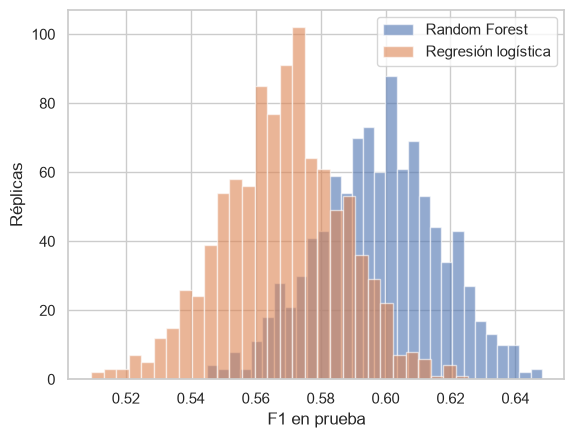

In [62]:
# Bootstrapping sobre prueba (ayudas: Bootstrapping e Intervalo de confianza por bootstrapping)
rng = np.random.default_rng(42)

y_real = np.asarray(y_test)
y_pred_rf = modelos["Random Forest"].predict(X_test_esc)
y_pred_lr = modelos["Regresión logística"].predict(X_test_esc)
n = len(y_real)
B = 1000

f1_boot_rf, f1_boot_lr = [], []
for _ in range(B):
    indices = rng.integers(0, n, n)
    f1_boot_rf.append(f1_score(y_real[indices], y_pred_rf[indices]))
    f1_boot_lr.append(f1_score(y_real[indices], y_pred_lr[indices]))
f1_boot_rf = np.array(f1_boot_rf)
f1_boot_lr = np.array(f1_boot_lr)

for nombre, y_pred, f1_boot in [("Random Forest", y_pred_rf, f1_boot_rf), ("Regresión logística", y_pred_lr, f1_boot_lr)]:
    metrica = f1_score(y_real, y_pred)
    limite_inferior, limite_superior = np.percentile(f1_boot, [2.5, 97.5])
    print(f"{nombre} · F1: {metrica:.3f}  IC 95 %: [{limite_inferior:.3f}; {limite_superior:.3f}]")

plt.hist(f1_boot_rf, bins=30, alpha=0.6, label="Random Forest")
plt.hist(f1_boot_lr, bins=30, alpha=0.6, label="Regresión logística")
plt.xlabel("F1 en prueba")
plt.ylabel("Réplicas")
plt.legend()
plt.show()

> **¿Entre qué valores puede estar el F1 de cada modelo en prueba?**
>
> Con 95 % de confianza, Random Forest entre 0,561 y 0,634 y la logística entre 0,531 y 0,603.
>
> **¿El F1 de validación queda dentro del intervalo de prueba?**
>
> Sí en los dos (0,584 y 0,551), así que el resultado de validación no fue suerte.
>
> **¿Los intervalos de los dos modelos se superponen?**
>
> Sí, bastante. Con esto solo no se puede decir que uno sea mejor; para eso está la prueba pareada.

<a id='s3-4-4'></a>
### 3.4.4 Diferencia pareada de F1

> Referencia: [P4 · A2 paso 4](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-2/)

> Esta sección responde:
> - ¿La diferencia de F1 entre Random Forest y la logística es significativa?

Diferencia observada de F1: 0.030  IC 95 %: [0.005; 0.055]  p-valor: 0.014
Significativa: True · Relevante: True


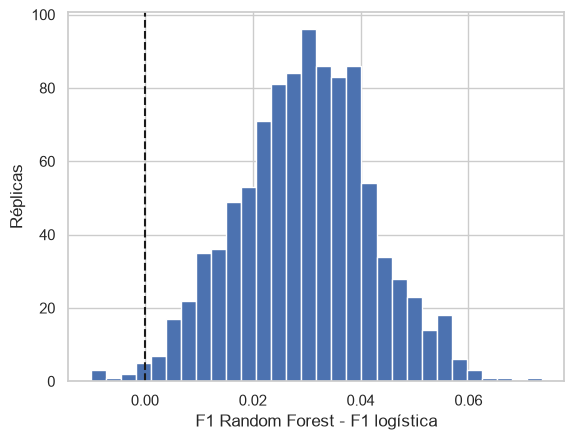

In [63]:
# Diferencia pareada de F1 en prueba (ayuda: Prueba A/B entre dos modelos). A = Random Forest, B = logística
rng = np.random.default_rng(42)
y_pred_a, y_pred_b = y_pred_rf, y_pred_lr
n_test = len(y_real)

boot_a = np.zeros(B)
boot_b = np.zeros(B)
for b in range(B):
    idx = rng.integers(0, n_test, n_test)   # los mismos clientes para los dos modelos
    boot_a[b] = f1_score(y_real[idx], y_pred_a[idx], zero_division=0)
    boot_b[b] = f1_score(y_real[idx], y_pred_b[idx], zero_division=0)

observada = f1_score(y_real, y_pred_a) - f1_score(y_real, y_pred_b)
d = boot_a - boot_b
inferior, superior = np.percentile(d, [2.5, 97.5])
p_boot = min(1.0, 2 * min(np.mean(d <= 0), np.mean(d >= 0)))
umbral = 0.02   # diferencia mínima que consideramos relevante

print(f"Diferencia observada de F1: {observada:.3f}  IC 95 %: [{inferior:.3f}; {superior:.3f}]  p-valor: {p_boot:.3f}")
print("Significativa:", inferior > 0 or superior < 0, "· Relevante:", abs(observada) >= umbral)

plt.hist(d, bins=30)
plt.axvline(0, color="k", linestyle="--")
plt.xlabel("F1 Random Forest - F1 logística")
plt.ylabel("Réplicas")
plt.show()

> **¿La diferencia de F1 entre Random Forest y la logística es significativa?**
>
> Sí. Random Forest tiene 0,030 más de F1 y el intervalo de la diferencia va de 0,005 a 0,055, sin incluir el 0 (p = 0,014). También es relevante, porque supera el umbral de 0,02. Los intervalos de 3.4.3 se superponen porque miran cada modelo por separado; la prueba pareada compara los dos sobre los mismos clientes.

<a id='s3-4-5'></a>
### 3.4.5 Prueba de McNemar

> Referencia: [P4 · A2 paso 5](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-2/)

> Esta sección responde:
> - ¿Un modelo se equivoca significativamente más que el otro, con todos los clientes y solo con los que abandonan?

In [64]:
from statsmodels.stats.contingency_tables import mcnemar

# Ayuda: Prueba de McNemar. A = Random Forest, B = logística
for titulo, filtro in [("Todos los clientes", y_real >= 0), ("Solo los que abandonan", y_real == 1)]:
    acierta_a = y_pred_a[filtro] == y_real[filtro]
    acierta_b = y_pred_b[filtro] == y_real[filtro]
    tabla = pd.crosstab(acierta_a, acierta_b, rownames=["A acierta"], colnames=["B acierta"])
    print(titulo)
    print(tabla)
    resultado = mcnemar(tabla.to_numpy(), exact=False, correction=True)
    print(f"McNemar: chi2 = {resultado.statistic:.2f}, p-valor = {resultado.pvalue:.4g}\n")

Todos los clientes
B acierta  False  True 
A acierta              
False        298     88
True         173   1441
McNemar: chi2 = 27.03, p-valor = 1.999e-07

Solo los que abandonan
B acierta  False  True 
A acierta              
False         84     36
True          13    274
McNemar: chi2 = 9.88, p-valor = 0.001673



> **¿Un modelo se equivoca significativamente más que el otro, con todos los clientes y solo con los que abandonan?**
>
> - Con todos los clientes, Random Forest se equivoca menos: acierta 173 clientes que la logística falla, contra 88 al revés (p < 0,001).
> - Solo con los que abandonan pasa lo contrario: la logística detecta 36 que Random Forest no, contra 13 al revés (p = 0,002).
>
> Random Forest acierta más en general porque da menos falsas alarmas, y la logística encuentra más clientes que se van. Coincide con el recall de 3.4.2.

<a id='s3-5'></a>
## 3.5 Qué impactó las métricas y qué mejorar

> Referencia: [P2 · A3 paso 10](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/) · [P4 · A1 paso 10](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-1/)

> Esta sección responde:
> - ¿Qué variables explican mejor el abandono?
> - ¿Qué ayudó a las métricas?
> - ¿Qué tipo de error comete más el modelo?
> - ¿Cómo se podría usar el umbral para detectar más clientes que abandonan y qué costo tendría?
> - ¿Qué se puede mejorar?

Intercepto: [0.67739962]


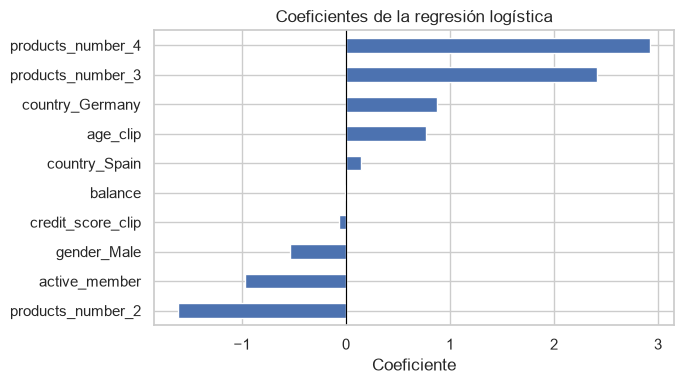

products_number_2   -1.62
active_member       -0.97
gender_Male         -0.54
credit_score_clip   -0.06
balance             -0.01
country_Spain        0.15
age_clip             0.77
country_Germany      0.88
products_number_3    2.41
products_number_4    2.93
dtype: float64


In [65]:
print("Intercepto:", modelos["Regresión logística"].intercept_)
coef = pd.Series(modelos["Regresión logística"].coef_[0], index=X_train.columns).sort_values()

coef.plot.barh(figsize=(7, 4))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente")
plt.title("Coeficientes de la regresión logística")
plt.tight_layout()
plt.show()
print(coef.round(2))

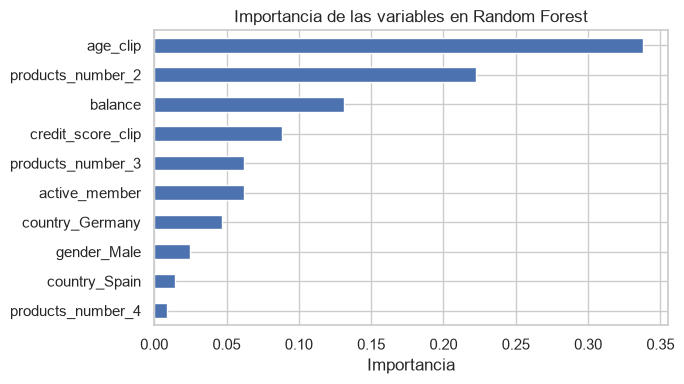

age_clip             0.338
products_number_2    0.222
balance              0.131
credit_score_clip    0.088
products_number_3    0.062
active_member        0.062
country_Germany      0.047
gender_Male          0.024
country_Spain        0.015
products_number_4    0.009
dtype: float64


In [66]:
importancias = pd.Series(modelos["Random Forest"].feature_importances_, index=X_train_esc.columns).sort_values()

importancias.plot.barh(figsize=(7, 4))
plt.xlabel("Importancia")
plt.title("Importancia de las variables en Random Forest")
plt.tight_layout()
plt.show()
print(importancias.sort_values(ascending=False).round(3))

In [67]:
# Qué pasa al bajar el umbral (en validación, para no ajustar nada con prueba)
y_prob = modelos["Random Forest"].predict_proba(X_val_esc)[:, 1]
filas = []
for umbral in [0.5, 0.4, 0.3, 0.2]:
    y_pred = (y_prob >= umbral).astype(int)
    filas.append({
        "umbral": umbral,
        "abandonos detectados": ((y_pred == 1) & (y_val == 1)).sum(),
        "falsas alarmas": ((y_pred == 1) & (y_val == 0)).sum(),
        "clientes contactados": y_pred.sum(),
        "precisión": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
    })
pd.DataFrame(filas).round(3)

,umbral,abandonos detectados,falsas alarmas,clientes contactados,precisión,recall
0,0.5,281,275,556,0.505,0.690
1,0.4,307,419,726,0.423,0.754
2,0.3,339,602,941,0.360,0.833
3,0.2,369,869,1238,0.298,0.907


> **¿Qué variables explican mejor el abandono?**
>
> Para Random Forest pesa más la edad, luego tener 2 productos y el balance. En la logística, tener 3 o 4 productos, ser de Alemania y la edad suben el riesgo; tener 2 productos, ser miembro activo y ser hombre lo bajan.
>
> **¿Qué ayudó a las métricas?**
>
> class_weight = "balanced": sin pesos el F1 de la logística baja de 0,567 a 0,509. También quedarse solo con las variables significativas y poner products_number en one-hot, porque 2 productos baja el riesgo y 3 o 4 lo suben.
>
> **¿Qué tipo de error comete más el modelo?**
>
> Falsas alarmas. En prueba Random Forest marca 266 clientes que se iban a quedar y se le escapan 120 que se van.
>
> **¿Cómo se podría usar el umbral para detectar más clientes que abandonan y qué costo tendría?**
>
> Bajándolo. En validación, con umbral 0,3 Random Forest detecta 339 de 407 (83 %) en vez de 281, pero las falsas alarmas pasan de 275 a 602 y hay que contactar a 941 clientes en vez de 556. Conviene si un contacto cuesta mucho menos que perder al cliente.
>
> **¿Qué se puede mejorar?**
>
> Elegir el umbral con los costos de la campaña (sección 5), agregar variables como balance en cero o edad × miembro activo, y tener más datos de prueba para que los intervalos sean más estrechos.

<a id='s4'></a>
# 4. Análisis Cualitativo de Resultados del Modelo

> Esta sección responde:
> - ¿Cómo decide Random Forest, a nivel global y en casos individuales?

Todo se hace sobre Random Forest, el modelo elegido, con clientes del conjunto de prueba.

<a id='s4-1'></a>
## 4.1 Comportamiento global

> Referencia: [P5 · A1 pasos 1, 5 y 6](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-1/) · [P5 · A3 pasos 1 y 4](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-3/)

> Esta sección responde:
> - ¿En qué rango de edad sube más el riesgo de abandono?
> - ¿El balance influye tanto como la edad?
> - ¿El efecto de la edad es igual para miembros activos e inactivos?
> - ¿Qué representa el valor base de SHAP y por qué no coincide con el 20 % de abandono?
> - ¿Qué variables pesan más según SHAP y en qué dirección mueven el riesgo?

In [68]:
from sklearn.base import BaseEstimator, ClassifierMixin

# Ayuda: Función de predicción para interpretar
columnas_modelo = list(X_train.columns)
modelo_clas = modelos["Random Forest"]


def predecir_abandono(X):
    X = pd.DataFrame(X, columns=columnas_modelo).copy()
    X[continuas_modelo] = escalador.transform(X[continuas_modelo])   # transform: se usa el escalador de entrenamiento
    return modelo_clas.predict_proba(X)[:, 1]


class ClasificadorDesdeFuncion(ClassifierMixin, BaseEstimator):
    def __init__(self, funcion):
        self.funcion = funcion

    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self.funcion(X)
        return np.column_stack([1 - p, p])


clasificador = ClasificadorDesdeFuncion(predecir_abandono).fit(X_train)
print("Coincide con el modelo:", np.allclose(predecir_abandono(X_test), modelo_clas.predict_proba(X_test_esc)[:, 1]))

Coincide con el modelo: True


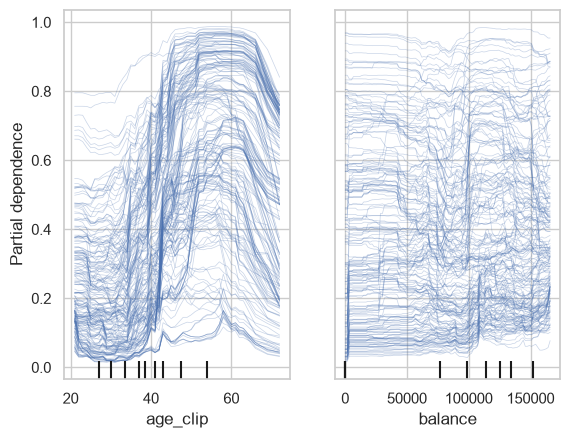

In [69]:
from sklearn.inspection import PartialDependenceDisplay

# Ayuda: Gráfico ICE
X_muestra = X_test.sample(200, random_state=42)

PartialDependenceDisplay.from_estimator(clasificador, X_muestra, ["age_clip", "balance"], kind="individual")
plt.show()

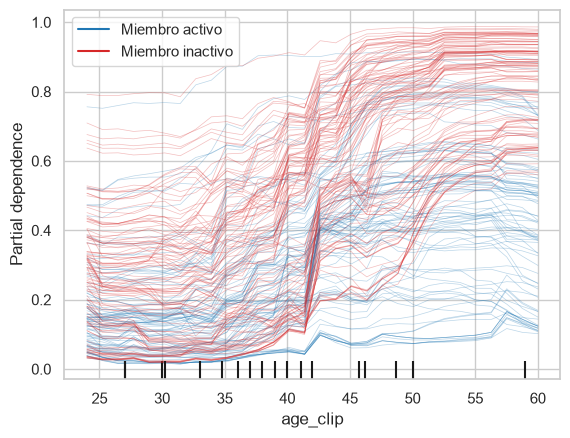

In [70]:
from matplotlib.lines import Line2D

columna = "age_clip"
grupo = X_muestra["active_member"] == 1
rejilla = {X_muestra.columns.get_loc(columna):
           np.linspace(X_muestra[columna].quantile(0.05), X_muestra[columna].quantile(0.95), 30)}

display = PartialDependenceDisplay.from_estimator(clasificador, X_muestra[grupo], [columna], kind="individual",
                                                  custom_values=rejilla, ice_lines_kw={"color": "tab:blue", "alpha": 0.3})
PartialDependenceDisplay.from_estimator(clasificador, X_muestra[~grupo], [columna], kind="individual", custom_values=rejilla,
                                        ax=display.axes_, ice_lines_kw={"color": "tab:red", "alpha": 0.3})
display.axes_[0, 0].legend(handles=[Line2D([0], [0], color="tab:blue", label="Miembro activo"),
                                    Line2D([0], [0], color="tab:red", label="Miembro inactivo")])
plt.show()

C:\Users\nrir\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Valor base: 0.5 · Abandono real en entrenamiento: 0.204


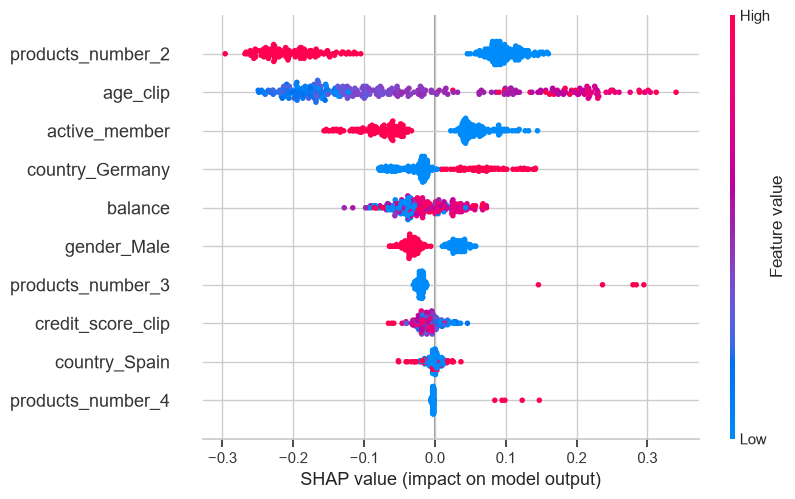

In [71]:
import shap

# Ayudas: Valores SHAP y Gráficos SHAP
explicador = shap.TreeExplainer(modelo_clas)
X_muestra = X_test.sample(300, random_state=42)

X_muestra_esc = X_muestra.copy()
X_muestra_esc[continuas_modelo] = escalador.transform(X_muestra[continuas_modelo])
valores = explicador(X_muestra_esc)[:, :, 1]   # clase positiva: abandona
valores.data = X_muestra.to_numpy()            # para ver la edad en años y no estandarizada

print("Valor base:", round(valores.base_values[0], 3), "· Abandono real en entrenamiento:", round(y_train.mean(), 3))
shap.plots.beeswarm(valores)

> **¿En qué rango de edad sube más el riesgo de abandono?**
>
> Entre los 40 y los 50 años, donde las curvas suben de golpe. Cerca de los 65 el riesgo vuelve a bajar.
>
> **¿El balance influye tanto como la edad?**
>
> No. Sus curvas son casi planas; solo hay un salto pequeño al pasar de 0 a tener saldo.
>
> **¿El efecto de la edad es igual para miembros activos e inactivos?**
>
> No. En los inactivos (rojo) el riesgo sube más y llega a 0,8 o 0,95; en los activos (azul) la mayoría se queda por debajo de 0,6.
>
> **¿Qué representa el valor base de SHAP y por qué no coincide con el 20 % de abandono?**
>
> Es la probabilidad promedio que da el modelo en entrenamiento: 0,5. No es 0,204 porque Random Forest se entrenó con class_weight = "balanced", que le da el mismo peso a las dos clases.
>
> **¿Qué variables pesan más según SHAP y en qué dirección mueven el riesgo?**
>
> Tener 2 productos baja mucho el riesgo, la edad alta lo sube, ser miembro activo lo baja y ser de Alemania lo sube. El balance, el género y el puntaje de crédito pesan poco. Coincide con los ICE.

<a id='s4-2'></a>
## 4.2 Predicciones individuales

> Referencia: [P5 · A2 pasos 1, 3, 5 y 6](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-2/) · [P5 · A3 paso 2](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-3/)

> Esta sección responde:
> - ¿Qué variables llevaron al modelo a cada decisión?
> - ¿Por qué se equivocó en el falso negativo y en el falso positivo?
> - ¿LIME y SHAP explican lo mismo?
> - ¿Dos clientes con probabilidad parecida llegan a ella por las mismas razones?

In [72]:
# Tres casos de la muestra de 300: el abandono detectado con más seguridad,
# el abandono con menos riesgo según el modelo y el cliente que se quedó con más riesgo
prob = predecir_abandono(X_muestra)
pred = (prob >= 0.5).astype(int)
y_muestra = y_test.loc[X_muestra.index].to_numpy()
posiciones = np.arange(len(X_muestra))

vp = posiciones[(y_muestra == 1) & (pred == 1)]
fn = posiciones[(y_muestra == 1) & (pred == 0)]
fp = posiciones[(y_muestra == 0) & (pred == 1)]
casos = {"Verdadero positivo": vp[prob[vp].argmax()],
         "Falso negativo": fn[prob[fn].argmin()],
         "Falso positivo": fp[prob[fp].argmax()]}

X_muestra.iloc[list(casos.values())].assign(caso=list(casos), probabilidad=prob[list(casos.values())].round(3),
                                            churn=y_muestra[list(casos.values())])

,age_clip,balance,credit_score_clip,active_member,country_Germany,country_Spain,gender_Male,products_number_2,products_number_3,products_number_4,caso,probabilidad,churn
2167,63.0,120916.52,701.0,0,1,0,1,0,1,0,Verdadero positivo,0.981,1
2692,58.0,0.00,535.0,1,0,1,1,1,0,0,Falso negativo,0.117,1
9066,47.0,130538.77,584.0,0,1,0,1,0,0,0,Falso positivo,0.951,0


Verdadero positivo · modelo: 0.981 · sustituto: 1.121 · R² local: 0.721


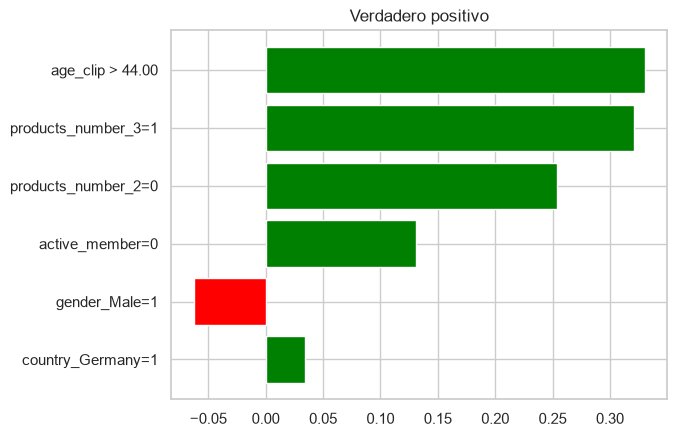

Falso negativo · modelo: 0.117 · sustituto: 0.364 · R² local: 0.721


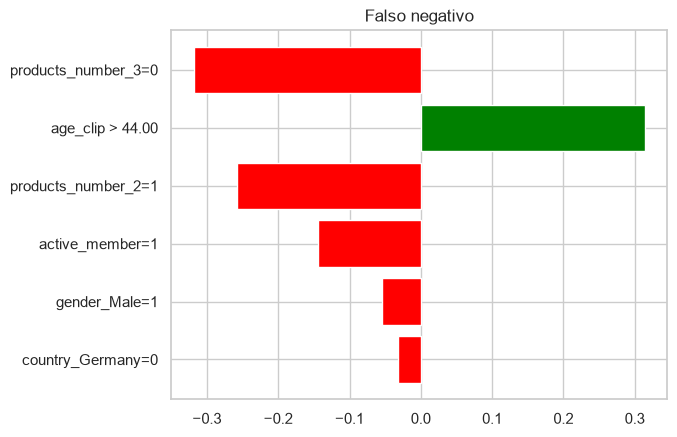

Falso positivo · modelo: 0.951 · sustituto: 0.795 · R² local: 0.712


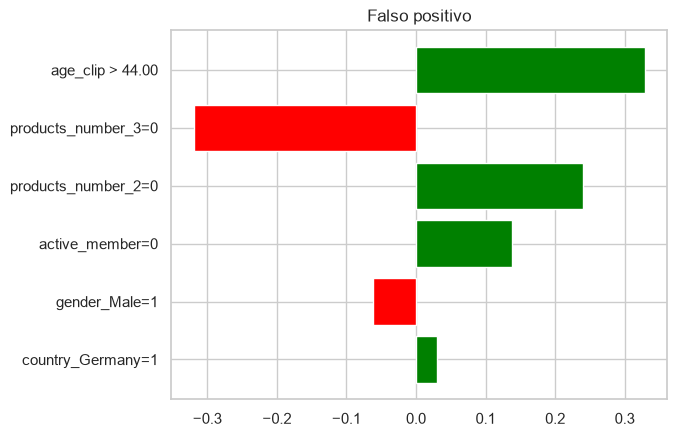

In [73]:
from lime.lime_tabular import LimeTabularExplainer

# Ayuda: LIME
indices_categoricas = [i for i, col in enumerate(columnas_modelo) if col not in continuas_modelo]
explicador_lime = LimeTabularExplainer(X_train.to_numpy(), feature_names=columnas_modelo, mode="classification",
                                       categorical_features=indices_categoricas, random_state=42)


def predecir_proba(X):
    p = predecir_abandono(X)
    return np.column_stack([1 - p, p])


for titulo, i in casos.items():
    x = X_muestra.iloc[i]
    explicacion = explicador_lime.explain_instance(x.to_numpy(), predecir_proba, num_features=6, num_samples=5000)
    print(f"{titulo} · modelo: {prob[i]:.3f} · sustituto: {explicacion.local_pred[0]:.3f} · R² local: {explicacion.score:.3f}")
    explicacion.as_pyplot_figure()
    plt.title(titulo)
    plt.show()

Verdadero positivo: 0.500 + 0.481 = 0.981


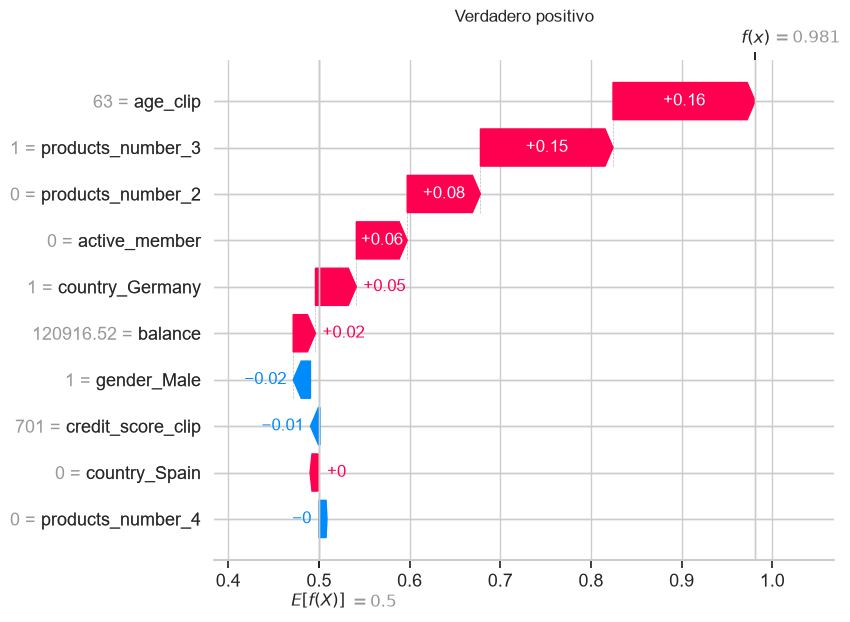

Falso negativo: 0.500 + -0.383 = 0.117


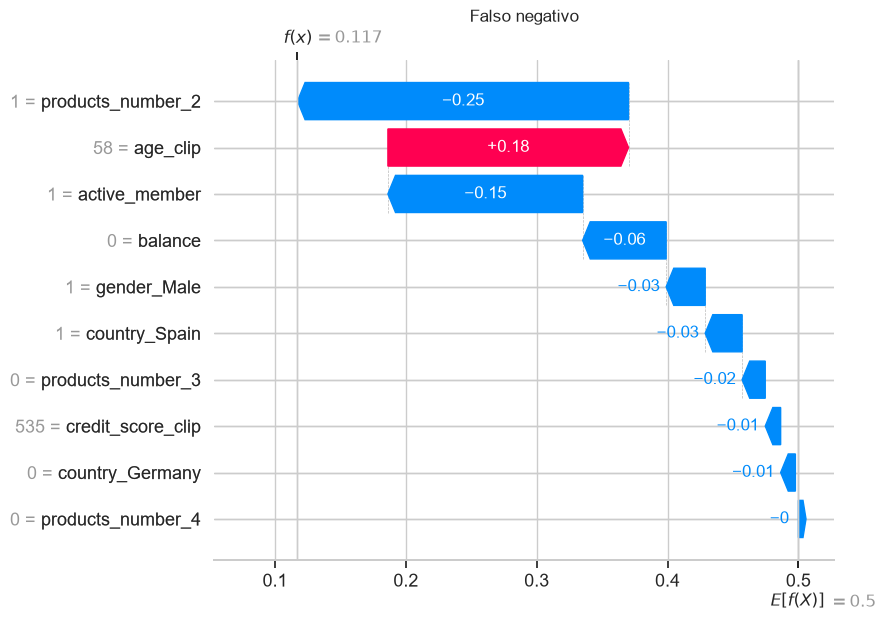

Falso positivo: 0.500 + 0.451 = 0.951


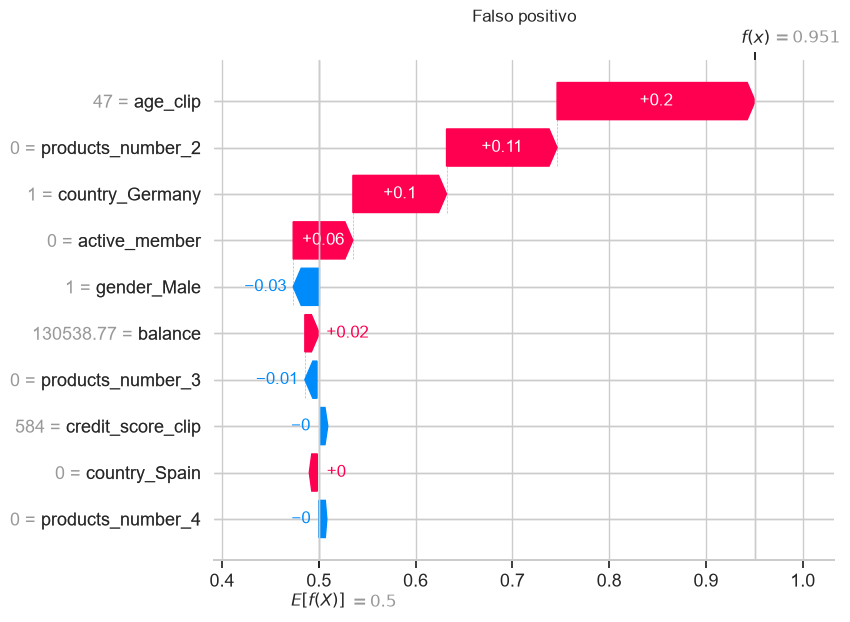

In [74]:
# Cascada SHAP de los mismos tres clientes: valor base + suma de valores SHAP = predicción
for titulo, i in casos.items():
    print(f"{titulo}: {valores.base_values[i]:.3f} + {valores.values[i].sum():.3f} = {valores.base_values[i] + valores.values[i].sum():.3f}")
    shap.plots.waterfall(valores[i], show=False)
    plt.title(titulo)
    plt.show()

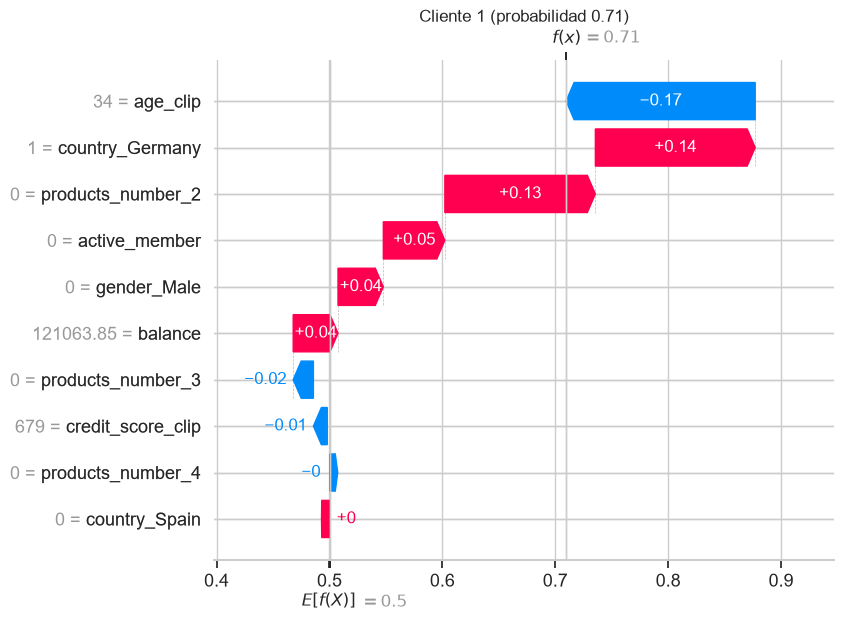

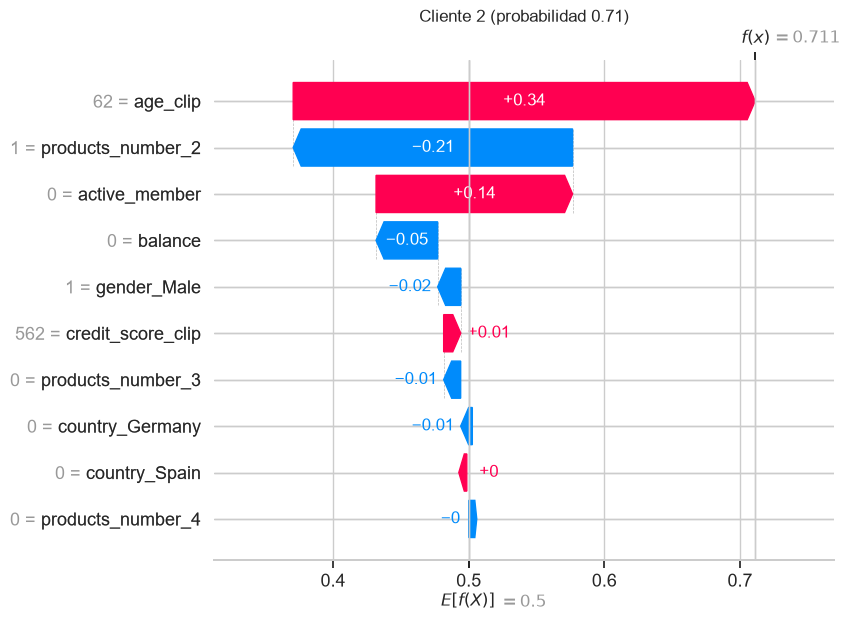

In [75]:
# Dos clientes en riesgo con casi la misma probabilidad (diferencia < 0,02) y razones lo más distintas posible
en_riesgo = posiciones[prob >= 0.5]
par, distancia = None, -1
for a in en_riesgo:
    for b in en_riesgo:
        if a < b and abs(prob[a] - prob[b]) < 0.02:
            d_shap = np.abs(valores.values[a] - valores.values[b]).sum()
            if d_shap > distancia:
                par, distancia = (a, b), d_shap

for k, i in enumerate(par, start=1):
    shap.plots.waterfall(valores[i], show=False)
    plt.title(f"Cliente {k} (probabilidad {prob[i]:.2f})")
    plt.show()

> **¿Qué variables llevaron al modelo a cada decisión?**
>
> - Verdadero positivo (0,98): 63 años, 3 productos, inactivo y de Alemania. Todo sube el riesgo.
> - Falso negativo (0,12): sus 58 años suben el riesgo, pero tener 2 productos y ser activo pesa más.
> - Falso positivo (0,95): 47 años, un solo producto, de Alemania e inactivo.
>
> **¿Por qué se equivocó en el falso negativo y en el falso positivo?**
>
> El falso negativo tenía casi todo a favor de quedarse y se fue igual, por algo que no está en los datos. El falso positivo tenía el perfil de quien se va y se quedó. Con solo estas 10 variables esos errores son difíciles de evitar.
>
> **¿LIME y SHAP explican lo mismo?**
>
> En lo principal sí: la edad, el número de productos y ser miembro activo salen arriba en los dos. Cambian los pesos: LIME le da mucho peso a no tener 3 productos y SHAP casi nada. Además, el sustituto de LIME no copia del todo al modelo (R² local ~0,72; en el falso negativo predice 0,36 y el modelo 0,12). En SHAP el valor base más la suma da exacto la predicción.
>
> **¿Dos clientes con probabilidad parecida llegan a ella por las mismas razones?**
>
> No. Los dos tienen 0,71. Al cliente 1 sus 34 años le bajan el riesgo, pero ser de Alemania y no tener 2 productos se lo suben. Al cliente 2 sus 62 años se lo suben mucho, aunque tiene 2 productos. A cada uno habría que ofrecerle algo distinto.

<a id='s4-3'></a>
## 4.3 Cómo funciona el modelo

> Referencia: [P5 · A1 paso 7](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-1/) · [P5 · A2 paso 7](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-2/) · [P5 · A3 paso 5](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/actividad-3/)

> Esta sección responde:
> - ¿Cómo decide el modelo, explicado en palabras del negocio?
> - ¿Qué le diría a un asesor que va a llamar a un cliente en riesgo?
> - ¿En qué se diferencian ICE, LIME y SHAP?
> - ¿Alguna de las tres técnicas demuestra que una variable causa el abandono?

> **¿Cómo decide el modelo, explicado en palabras del negocio?**
>
> Mira sobre todo la edad, el número de productos y si el cliente es activo. El riesgo sube mucho entre los 40 y 50 años, con 1, 3 o 4 productos y en clientes inactivos; con 2 productos es más bajo. Ser de Alemania suma riesgo y el balance pesa poco.
>
> **¿Qué le diría a un asesor que va a llamar a un cliente en riesgo?**
>
> Que revise las razones de ese cliente y no solo su probabilidad. Si es inactivo, ofrecerle algo que lo haga usar el banco; si tiene un solo producto, ofrecerle un segundo. El modelo también se equivoca, como en el falso positivo.
>
> **¿En qué se diferencian ICE, LIME y SHAP?**
>
> | Técnica | Alcance | Pregunta que responde | Costo | Estabilidad | Limitaciones |
> |---|---|---|---|---|---|
> | ICE | Global, una curva por cliente | ¿Cómo cambia el riesgo si cambia una variable? | Bajo | Alta | Una variable a la vez, no sirve bien con one-hot y puede crear clientes irreales |
> | LIME | Local, un cliente | ¿Por qué el modelo predijo esto para este cliente? | Medio: miles de simulaciones por cliente | Baja: cambia con la semilla | Es una aproximación lineal y no siempre copia bien al modelo |
> | SHAP | Local y global | ¿Cuánto aporta cada variable a la predicción? | Bajo para árboles | Alta: es exacto | Con variables correlacionadas reparte el efecto entre ellas |
>
> **¿Alguna de las tres técnicas demuestra que una variable causa el abandono?**
>
> No. Explican cómo usa el modelo las variables, no qué causa el abandono. Que tener 3 productos suba el riesgo no significa que venderle un tercer producto a alguien haga que se vaya.

<a id='s5'></a>
# 5. Generación de Valor

> Esta sección responde:
> - ¿Cuánto gana el banco con el modelo y cuándo recupera la inversión?

<a id='s5-1'></a>
## 5.1 Supuestos y fuentes

> Referencia: [P4 · A3 pasos 1 y 2](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/)

> Esta sección responde:
> - ¿Qué supuestos y fuentes se usan?

Del enunciado: banco de 20.000 clientes, 15 % de abandono anual, la campaña convence al 30 % de los que se iban a ir, se paga por todos los contactados y el ingreso anual por cliente es de 500.000 a 900.000 pesos.

Fuentes de los supuestos propios:
- Costo de una llamada de agente en Colombia: entre USD 0,45 y 1,50 ([Talkyria, 2026](https://talkyria.com/blog/cuanto-cuesta-call-center-ecommerce-colombia)); la hora de agente entre USD 13 y 19 ([Call Force, 2026](https://callforce.global/services/colombia/)).
- Cuota de manejo de tarjeta débito: entre $12.800 y $14.990 al mes en los bancos que cobran ([Pulzo](https://www.pulzo.com/economia/av-villas-bancolombia-bancos-que-cobran-mayores-cuotas-manejo-para-ahorrar-PP1176541); [Noticias RCN, 2026](https://www.noticiasrcn.com/economia/cuota-de-manejo-bancos-mas-caros-y-gratuitos-1045068)).
- TRM de inicios de noviembre de 2026: ~$3.230 por dólar ([dolar-colombia.com](https://www.dolar-colombia.com/2026-11-06)).
- Salario científico de datos: ~$6,9 millones al mes en Colombia ([Indeed](https://co.indeed.com/career/data-scientist/salaries)) y mediana de $7,6 millones en Bogotá ([Glassdoor](https://www.glassdoor.com/Salaries/bogot%C3%A1-bogota-cient%C3%ADfico-de-datos-salary-SRCH_IL.0,13_IC4309640_KO14,33.htm)).
- Salario ingeniero de datos: oferta de $7,1 millones ([Elempleo](https://www.elempleo.com/co/ofertas-empleo/trabajo-data-engineer)); ingeniero de machine learning: ~$7 millones en Bogotá ([UNIR](https://colombia.unir.net/actualidad-unir/cuanto-gana-ingeniero-inteligencia-artificial/)).

In [76]:
# Supuestos (pesos colombianos). Notación de la ayuda "Calcular el impacto de un modelo"
clientes = 20_000
tasa_abandono = 0.15                 # anual, del enunciado
r = 0.30                             # éxito de la oferta
V = 700_000                          # valor de un cliente retenido: un año de ingreso (punto medio de 500.000 a 900.000)
TRM = 3_230                          # pesos por dólar, noviembre de 2026
c = 1.0 * TRM + 3 * 14_000           # costo por contactado: llamada (USD 1) + tres meses sin cuota de manejo
M = clientes * tasa_abandono / 12    # clientes que abandonan al mes

print(f"c = {c:,.0f} pesos · M = {M:.0f} clientes al mes")

c = 45,230 pesos · M = 250 clientes al mes


In [77]:
# Presupuesto de implementación, con la misma estructura que el de la práctica
carga = 1.5   # salario + prestaciones

presupuesto = pd.DataFrame({
    "rubro": ["Científico de datos (3 meses)", "Ingeniero de datos (3 meses)", "Ingeniero de ML (2 meses)",
              "Líder de negocio al 50 % (3 meses)", "Nube, USD 400 al mes (3 meses)",
              "Integración con el CRM del banco", "Capacitación del equipo comercial"],
    "total": [7_000_000 * carga * 3, 7_100_000 * carga * 3, 7_000_000 * carga * 2,
              10_000_000 * 0.5 * carga * 3, 400 * TRM * 3, 25_000_000, 10_000_000],
})
presupuesto.loc[len(presupuesto)] = ["Contingencia (10 %)", 0.10 * presupuesto["total"].sum()]
I_proy = presupuesto["total"].sum()

print(f"Inversión: {I_proy:,.0f} pesos · personas: {presupuesto['total'].iloc[:4].sum() / I_proy:.0%}")
presupuesto.style.format({"total": "{:,.0f}"})

Inversión: 160,408,600 pesos · personas: 67%


,rubro,total
0,Científico de datos (3 meses),"31,500,000"
1,Ingeniero de datos (3 meses),"31,950,000"
2,Ingeniero de ML (2 meses),"21,000,000"
3,Líder de negocio al 50 % (3 meses),"22,500,000"
4,"Nube, USD 400 al mes (3 meses)","3,876,000"
5,Integración con el CRM del banco,"25,000,000"
6,Capacitación del equipo comercial,"10,000,000"
7,Contingencia (10 %),"14,582,600"


> **¿Qué supuestos y fuentes se usan?**
>
> Del enunciado salen los clientes, la tasa de abandono, el éxito de la campaña y el ingreso; del ingreso se usa el punto medio (700.000). El costo por contactado es 45.230 pesos: una llamada (USD 1) más tres meses sin cuota de manejo. La inversión es de 160 millones, el 67 % en el equipo (salarios de mercado por 1,5 de prestaciones). Se asume que retener a un cliente vale un año de ingreso.

<a id='s5-2'></a>
## 5.2 Ganancia esperada por estimación

> Referencia: [P4 · A3 pasos 3 y 4](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/)

> Esta sección responde:
> - ¿Cómo queda la matriz costo-beneficio?
> - ¿Cuál es la ganancia esperada por cliente y por mes?
> - ¿Cómo afecta que el banco tenga 15 % de abandono y no 20,4 %?

In [78]:
# Matriz costo-beneficio: VP = r·V - c, FP = -c, FN = VN = 0
print(f"VP = {r * V - c:,.0f} · FP = {-c:,.0f} · FN = VN = 0")


def beneficio_mensual(y_real, y_pred, V=V, r=r, c=c):
    """B = R · M · (r·V - c/P), con la precisión ajustada al 15 % de abandono del banco."""
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    R = recall_score(y_real, y_pred)
    fpr = ((y_pred == 1) & (y_real == 0)).sum() / (y_real == 0).sum()
    P = tasa_abandono * R / (tasa_abandono * R + (1 - tasa_abandono) * fpr)   # el dataset tiene 20,4 % y el banco 15 %
    return R, P, R * M * (r * V - c / P)


filas = []
for nombre, modelo in modelos.items():
    R, P, B_mes = beneficio_mensual(y_test, modelo.predict(X_test_esc))
    filas.append({"modelo": nombre, "recall": round(R, 3), "precisión con 15 %": round(P, 3),
                  "beneficio mensual": round(B_mes), "ganancia por cliente al año": round(B_mes * 12 / clientes)})
impacto = pd.DataFrame(filas).set_index("modelo")
impacto

VP = 164,770 · FP = -45,230 · FN = VN = 0


,recall,precisión con 15 %,beneficio mensual,ganancia por cliente al año
modelo,,,,
Regresión logística,0.762,0.364,16331581,9799
Random Forest,0.705,0.427,18347874,11009


> **¿Cómo queda la matriz costo-beneficio?**
>
> Un abandono detectado vale 0,30 × 700.000 − 45.230 = 164.770 pesos y una falsa alarma cuesta 45.230. Los falsos negativos y los verdaderos negativos valen 0, porque sin modelo tampoco se haría nada con ellos.
>
> **¿Cuál es la ganancia esperada por cliente y por mes?**
>
> Con umbral 0,5, Random Forest deja 11.009 pesos al año por cliente evaluado, unos 18,3 millones al mes. La logística deja 9.799 por cliente, unos 16,3 millones al mes. Random Forest gana aunque detecta menos abandonos, porque contacta a menos clientes que no se iban a ir.
>
> **¿Cómo afecta que el banco tenga 15 % de abandono y no 20,4 %?**
>
> Entre los contactados hay menos clientes que se van, así que la precisión baja: Random Forest pasa de 0,519 a 0,427 y la logística de 0,453 a 0,364.

<a id='s5-3'></a>
## 5.3 Punto de equilibrio

> Referencia: [P4 · A3 pasos 4 y 5](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/)

> Esta sección responde:
> - ¿En cuánto tiempo se recupera la inversión y cuál es el ROI a 12 meses?
> - ¿Qué precisión necesita el modelo para no perder plata?

Precisión de equilibrio: 0.215
Regresión logística: recupera la inversión en 9.8 meses · ROI a 12 meses: 22%
Random Forest: recupera la inversión en 8.7 meses · ROI a 12 meses: 37%


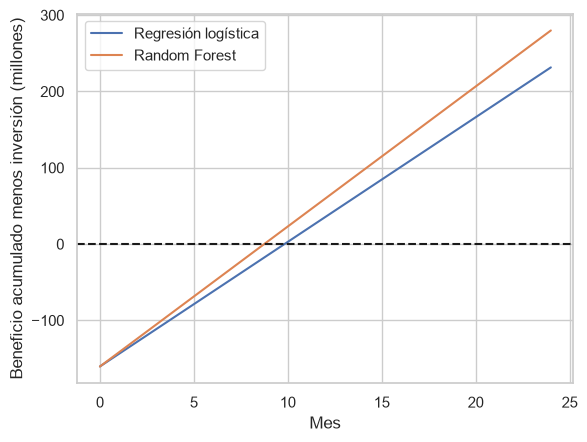

In [79]:
P_e = c / (r * V)
print(f"Precisión de equilibrio: {P_e:.3f}")

meses = np.arange(0, 25)
for nombre in modelos:
    B_mes = impacto.loc[nombre, "beneficio mensual"]
    t = I_proy / B_mes
    roi = (12 * B_mes - I_proy) / I_proy
    print(f"{nombre}: recupera la inversión en {t:.1f} meses · ROI a 12 meses: {roi:.0%}")
    plt.plot(meses, (B_mes * meses - I_proy) / 1e6, label=nombre)
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Mes")
plt.ylabel("Beneficio acumulado menos inversión (millones)")
plt.legend()
plt.show()

> **¿En cuánto tiempo se recupera la inversión y cuál es el ROI a 12 meses?**
>
> Random Forest la recupera en 8,7 meses, con un ROI de 37 % a 12 meses. La logística en 9,8 meses, con 22 %.
>
> **¿Qué precisión necesita el modelo para no perder plata?**
>
> 0,215. Por debajo de eso cada contacto cuesta más de lo que recupera. Los dos modelos están por encima (0,427 y 0,364).

<a id='s5-4'></a>
## 5.4 Estimación paramétrica

> Referencia: [P4 · A3 paso 6](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/)

> Esta sección responde:
> - ¿Qué umbral maximiza el beneficio?
> - ¿Cómo cambia la ganancia si cambian el ingreso, la tasa de éxito o el costo por contacto?

In [80]:
# El umbral se elige en validación
filas = []
for nombre, modelo in modelos.items():
    prob_val = modelo.predict_proba(X_val_esc)[:, 1]
    for umbral_decision in [0.3, 0.4, 0.5, 0.6, 0.7]:
        R, P, B_mes = beneficio_mensual(y_val, (prob_val >= umbral_decision).astype(int))
        filas.append({"modelo": nombre, "umbral": umbral_decision, "recall": round(R, 3),
                      "precisión con 15 %": round(P, 3), "beneficio mensual": round(B_mes)})
umbrales = pd.DataFrame(filas)
umbrales

,modelo,umbral,recall,precisión con 15 %,beneficio mensual
0,Regresión logística,0.3,0.870,0.252,6666421
1,Regresión logística,0.4,0.794,0.296,11372466
2,Regresión logística,0.5,0.730,0.354,14975627
3,Regresión logística,0.6,0.609,0.407,15044255
4,Regresión logística,0.7,0.491,0.483,14288956
5,Random Forest,0.3,0.833,0.280,10095744
6,Random Forest,0.4,0.754,0.336,14217899
7,Random Forest,0.5,0.690,0.414,17378603
8,Random Forest,0.6,0.602,0.505,18119388
9,Random Forest,0.7,0.494,0.596,16562228


In [81]:
# Y se reporta en prueba
mejores = umbrales.loc[umbrales.groupby("modelo")["beneficio mensual"].idxmax(), ["modelo", "umbral"]]
for nombre, umbral_decision in mejores.itertuples(index=False):
    y_pred = (modelos[nombre].predict_proba(X_test_esc)[:, 1] >= umbral_decision).astype(int)
    R, P, B_mes = beneficio_mensual(y_test, y_pred)
    print(f"{nombre} · umbral {umbral_decision}: {B_mes:,.0f} al mes · recupera en {I_proy / B_mes:.1f} meses · "
          f"ROI a 12 meses: {(12 * B_mes - I_proy) / I_proy:.0%}")

Random Forest · umbral 0.6: 19,955,416 al mes · recupera en 8.0 meses · ROI a 12 meses: 49%
Regresión logística · umbral 0.6: 16,077,119 al mes · recupera en 10.0 meses · ROI a 12 meses: 20%


In [82]:
# Random Forest con su mejor umbral, cambiando un supuesto a la vez
umbral_rf = mejores.set_index("modelo").loc["Random Forest", "umbral"]
y_pred_umbral = (modelos["Random Forest"].predict_proba(X_test_esc)[:, 1] >= umbral_rf).astype(int)

escenarios = {"Base": {}, "V = 500.000": {"V": 500_000}, "V = 900.000": {"V": 900_000},
              "r = 15 %": {"r": 0.15}, "r = 45 %": {"r": 0.45}, "c = 10.000": {"c": 10_000}, "c = 80.000": {"c": 80_000}}
filas = []
for escenario, cambio in escenarios.items():
    _, _, B_mes = beneficio_mensual(y_test, y_pred_umbral, **cambio)
    filas.append({"escenario": escenario, "beneficio mensual": round(B_mes),
                  "meses para recuperar": round(I_proy / B_mes, 1), "ROI a 12 meses": round((12 * B_mes - I_proy) / I_proy, 2)})
pd.DataFrame(filas).set_index("escenario")

,beneficio mensual,meses para recuperar,ROI a 12 meses
escenario,,,
Base,19955416,8.0,0.49
V = 500.000,10594237,15.1,-0.21
V = 900.000,29316596,5.5,1.19
r = 15 %,3573352,44.9,-0.73
r = 45 %,36337480,4.4,1.72
c = 10.000,29932222,5.4,1.24
c = 80.000,10108879,15.9,-0.24


> **¿Qué umbral maximiza el beneficio?**
>
> 0,6 en los dos modelos. Como cada contacto cuesta 45.230 pesos, conviene ser un poco menos alarmista: se detectan menos abandonos, pero bajan más las falsas alarmas. En prueba, Random Forest con 0,6 deja unos 20 millones al mes, recupera la inversión en 8 meses y su ROI a 12 meses sube de 37 % a 49 %. En la logística no ayuda (16,1 frente a 16,3 millones).
>
> **¿Cómo cambia la ganancia si cambian el ingreso, la tasa de éxito o el costo por contacto?**
>
> Lo que más pesa es el éxito de la campaña: con 15 % la inversión tarda casi 45 meses en recuperarse y con 45 % solo 4,4. Con un ingreso de 500.000 o un contacto de 80.000 tarda unos 15 a 16 meses y el ROI a 12 meses sale negativo. Con un ingreso de 900.000 o un contacto de 10.000 tarda unos 5,5.

<a id='s5-5'></a>
## 5.5 Limitaciones

> Referencia: [P4 · A3 paso 10](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/)

> Esta sección responde:
> - ¿Qué limita al modelo y al valor calculado?

> **¿Qué limita al modelo y al valor calculado?**
>
> - Los datos son de clientes europeos y se aplican a un banco colombiano; el país no tiene equivalente.
> - El dataset tiene 20,4 % de abandono y el banco 15 %. Se ajustó la precisión, pero el modelo no se reentrenó.
> - El 30 % de éxito es un supuesto y es lo que más mueve el resultado.
> - Retener a un cliente se valora como un año de ingreso. Si se queda más tiempo, el valor sería mayor.
> - No se cuentan costos después del lanzamiento (nube, mantenimiento, reentrenamiento) ni llamadas sin contestar.
> - Los costos salen de proveedores y portales de empleo, no de cotizaciones reales.
> - El F1 en prueba puede variar unos ±0,04 (sección 3.4.3), así que el beneficio también.

<a id='s6'></a>
# 6. Insights e informe ejecutivo

> Esta sección responde:
> - ¿Cuáles son los hallazgos más importantes y qué se recomienda al negocio?

<a id='s6-1'></a>
## 6.1 Hallazgos principales

> Esta sección responde:
> - ¿Qué se descubrió sobre los clientes que abandonan?

<a id='s6-2'></a>
## 6.2 Resultados del modelo

> Esta sección responde:
> - ¿Qué tan bueno es el modelo y cuánto valor genera?

<a id='s6-3'></a>
## 6.3 Recomendación final para el negocio

> Esta sección responde:
> - ¿Qué debe hacer el banco?

<a id='s7'></a>
# 7. Declaración de uso de IA generativa

En esta sección:
- Modelos de IA usados, quién los usó y el porcentaje de ayuda (7.1).
- Prompts literales y el plan aprobado (7.2).

<a id='s7-1'></a>
## 7.1 Modelos y porcentaje de ayuda

| Usado por | Modelo | Herramienta | Uso | Porcentaje de ayuda |
|---|---|---|---|---|
| Samuel Charry | Claude Opus 5.5 (Anthropic) | Claude Code | Reorganización y formato del notebook: índice con subíndices, viñetas bajo cada título, referencias a las prácticas del curso y limpieza de negrillas. No redactó análisis ni conclusiones | 15%|

<a id='s7-2'></a>
## 7.2 Prompts empleados

Prompt 1 — Samuel Charry · objetivo: reorganizar el notebook (índice, subtítulos y referencias). Texto literal:

```text
Quiero que le hagas un refactor al taller no cambies su contenido solo su organización, pongas un indice con sub indices los cuales hagan referencia directa a los puntos de las practicas, pero siempre PONIENDO EXPLICITAMENTE SUBTITULOS DE LO QUE PIDE EL TALLER 2 ejemplo el 1 pide dimensiones del data set, tipos de variables y graficos etc etc ..., mi profesor tiene que calificar 40 talleres y muchos van a estar llenos de ai slop para no cometer ese error y para obtener la mejor calificación deberia ser facil de leer, rapido de encontrar lo que pide y correctamente refernciado en todo momento. Así el trabajo no esta lleno de contenido sin significado ni valor
```

Plan propuesto por el modelo para el prompt 1 y aprobado por Samuel Charry antes de implementarlo:

<details>
<summary>Ver plan completo</summary>

#### Plan: reorganizar `Taller2_CDA.ipynb` (solo estructura)

##### Contexto
El profesor califica unos 40 talleres. Este debe ser rápido de leer y de recorrer: cada requisito del Taller 2 tiene que aparecer como subtítulo explícito, y cada subtítulo debe citar la práctica del sitio en la que se basa (https://datascience-uniandes.github.io/PracticasMachineLearning/). **No se cambia contenido**: no se reescribe texto ni se modifica código ni sus salidas. Solo se agregan títulos, un índice con subíndices y líneas de referencia, y se dividen o mueven celdas markdown.

##### Reglas
- **El orden de las celdas de código no cambia.** Así la ejecución secuencial da los mismos resultados (por ejemplo, la celda que cuenta duplicados sigue antes de `drop_duplicates`). Solo se insertan celdas markdown entre ellas.
- Los textos de las celdas markdown existentes se conservan literalmente. Solo se reemplazan los títulos viejos (`### Cargar el dataset`, `## Clipping de Outliers`, etc.) por títulos numerados. La celda 6 se divide en dos (bullets de dimensiones/nulos y tabla de tipos) para ubicar cada parte bajo su subtítulo.
- Formato fijo bajo cada subtítulo, en una sola línea:
  `> **Pide el taller:** <texto del enunciado> · **Referencia:** [Práctica 2 · Actividad 1 · paso 2](url)`
- Anclas explícitas `<a id="s1-2"></a>` en cada título, y el índice enlaza a `#s1-2`. Funciona en Jupyter, VS Code y Colab. El índice actual no funciona porque usa anclas con tildes y la sección 6 no existe.
- Las secciones aún vacías (2 a 7) quedan con sus subtítulos, su referencia y la marca *(pendiente)*, sin contenido inventado.

##### Nueva estructura (los números `[n]` son las celdas actuales)

**Portada** [0] · **Índice** (nuevo, anidado, reemplaza [1]) · **Mapa de referencias** (nuevo: tabla "Punto del taller → Práctica / Actividad / pasos" con enlaces)

**1. Entendimiento y preparación de los datos** [2] (enunciado del taller tal cual)
- 1.1 Carga del dataset → P2-A1 paso 1 → [4], [5]
- 1.2 Dimensiones del dataset → P2-A1 paso 2 → bullet "Dimensiones" de [6], [7]
- 1.3 Tipos de variables → P2-A1 paso 2 → tabla y nota de [6], [8], [9]
- 1.4 Gráficos de distribución → P2-A1 pasos 3–5
  - 1.4.1 Variables continuas (paso 3) → [10] sin su título, [11], [12], [13]
  - 1.4.2 Variables categóricas y binarias (paso 4) → [14] sin su título, [15], [16], [17]
  - 1.4.3 Variable objetivo `churn` y desbalance (paso 5) → [19], [20]
- 1.5 Indicadores importantes: calidad de datos → P2-A1 paso 6 → bullets "Nulos" e "Inconsistencias" de [6] (unicidad, completitud, consistencia), [21]
- 1.6 Preparación de los datos → P2-A1 pasos 7–10
  - 1.6.1 Duplicados (paso 7) → [22]
  - 1.6.2 Valores inválidos: validez y clipping al rango (pasos 6 y 8) → [23], [24], [25]
  - 1.6.3 Outliers: IQR y clipping por percentiles (paso 9) → [26]–[30], [32], [33] ([31] pasa a ser este subtítulo)
  - 1.6.4 Valores nulos (paso 10) → *(pendiente)*
- 1.7 Selección de variables y codificación → P2-A2 pasos 2–7 → *(pendiente)*

**2. Entrenamiento del modelo** [34]
- 2.1 División de los datos → P2-A2 paso 8
- 2.2 Modelos y estimación de hiperparámetros
  - 2.2.1 Modelos básicos: logística, árbol, KNN → P2-A3 pasos 1–4
  - 2.2.2 Ensambles: RF, GB, votación, stacking → P2-A4 pasos 1–5
  - 2.2.3 Red neuronal (opcional) → P2-A5 pasos 1–3
- 2.3 Selección del modelo → P2-A3 paso 8 · P2-A4 paso 9 · P2-A5 paso 5

**3. Análisis cuantitativo** [35]
- 3.1 Métricas de evaluación (matriz de confusión, exactitud, precisión, recall, F1) → P2-A3 paso 5 · P2-A4 paso 6
- 3.2 Curvas precisión-recall y ROC → P2-A3 pasos 6–7 · P2-A4 pasos 7–8
- 3.3 Significado de las métricas y su valor para la empresa → P2-A3 paso 10
- 3.4 Justificación del modelo elegido (prueba, intervalos, pruebas A/B) → P2-A3 paso 9 · P2-A4 paso 10 · P4-A1 pasos 7–9 · P4-A2 pasos 4–6
- 3.5 Qué impactó las métricas y oportunidades de mejora → P2-A3 paso 10 · P4-A1 paso 10

**4. Análisis cualitativo** [36]
- 4.1 Comportamiento global (ICE, enjambre SHAP) → P5-A1 pasos 5–6 · P5-A3 paso 4
- 4.2 Muestra de predicciones individuales (VP, FN, FP con LIME y SHAP) → P5-A2 pasos 5–6 · P5-A3 pasos 2–3
- 4.3 Interpretación: cómo funciona el modelo → P5-A1 paso 7 · P5-A2 paso 7 · P5-A3 paso 5

**5. Generación de valor** [37]
- 5.1 Supuestos y fuentes (20.000 clientes, churn 15 %, éxito 30 %, ingreso COP 500k–900k, costo por contacto e implementación) → P4-A3 pasos 1–2 + notas al pie del taller
- 5.2 Ganancia esperada por estimación (matriz costo-beneficio) → P4-A3 pasos 3–4
- 5.3 Punto de equilibrio (break-even) → P4-A3 pasos 5 y 7
- 5.4 Estimación paramétrica (sensibilidad y umbral) → P4-A3 paso 6
- 5.5 Limitaciones del modelo y del valor generado → P4-A3 paso 10

**6. Insights e informe ejecutivo** (nuevo) → 6.1 Hallazgos principales · 6.2 Resultados del modelo · 6.3 Recomendación final → P2-A5 paso 7 · P4-A3 paso 10

**7. Declaración de uso de IA generativa** (nuevo) → 7.1 Modelos y porcentaje de ayuda · 7.2 Prompts empleados (sin referencia: no hay práctica equivalente)

Nota: [3] y [18] solo contienen títulos viejos; los reemplazan 1.1 y 1.4.3.

##### Implementación
1. Copia de respaldo: `Taller2_CDA.backup.ipynb`.
2. Un script de Python en el scratchpad carga el JSON y arma la nueva lista de celdas: reutiliza las celdas originales por `id` (con sus salidas intactas), divide [6] e inserta las celdas markdown nuevas. Guarda con `ensure_ascii=False, indent=1` y conserva `metadata`, `nbformat` y `nbformat_minor`.

##### Verificación
- El script compara antes y después:
  - las fuentes y salidas de las celdas de código son idénticas y siguen en el mismo orden relativo;
  - cada línea de texto de las celdas markdown originales aparece en el nuevo notebook, salvo los títulos reemplazados.
- `nbformat.validate` pasa sin errores.
- Cada enlace `#sX-Y` del índice tiene su `<a id>`, y cada URL de referencia responde 200.
- Abrir el notebook en Chrome o VS Code y revisar visualmente el índice y algunos saltos.

</details>

Prompt 2 — Sergio Perez · objetivo: Corregir ortografía, organización. Texto literal:

```text
Quiero que revises todas las celdas de texto y codigo y corrijas errores ortograficos, typos y de estilo. NO quiero que modifiques el contenido de fondo
```

Prompt 3 — Sergio Perez · objetivo: Generar el archivo README. Texto literal:

```text
Genera el archivo README, incluye los nombres de los archivos y el contenido de cada uno, ademas quiero que especifiques en que archivo se encuentra cada punto del taller y las instrucciones de como ejecutar los notebooks
```